# Análise exploratória dos fatores associados à evasão — Pré-defesa

**Tema:** Análise de fatores associados à evasão de estudantes do ensino superior utilizando técnicas de análise de dados e aprendizado de máquina — um estudo de caso no Inatel.

A análise acompanha estudantes ao longo dos semestres, descreve os eventos institucionais de saída e examina o que aparece antes deles. As perguntas seguem a sequência do notebook original: população, eventos, desempenho, frequência, finanças, contexto familiar e trajetória.

Desistência, abandono, cancelamento e desligamento formam o conjunto provisório de **eventos de saída observados**. Ele não define evasão definitiva. Os resultados são descritivos; diferenças entre grupos não demonstram causas.

Execute todas as células em ordem. O CSV é lido do caminho externo configurado. Os caminhos são configuráveis na célula seguinte ou pelas variáveis de ambiente `TCC_CSV_PATH`, `TCC_LEGENDA_PATH` e `TCC_NOTEBOOK_ORIGINAL_PATH`. Identificadores ficam em memória e as saídas são agregadas. A auditoria por seção está em `relatorio_alteracoes_v2.md`.


## 1. Antes de procurar os fatores, o que exatamente a nossa base representa?

Quantos estudantes, registros e semestres compõem a extração? A unidade de uma linha também importa: registros acadêmicos e ocorrências administrativas podem aparecer juntos no mesmo aluno/semestre. Esse entendimento antecede as comparações, seguindo a etapa de entendimento dos dados do CRISP-DM. A perspectiva de Tinto orienta a leitura da saída como parte de uma trajetória.


In [ ]:
%pip install pandas numpy matplotlib scipy

In [2]:
import hashlib
import json
import os
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from scipy.stats import chi2_contingency

CSV_PATH = Path(os.environ.get("TCC_CSV_PATH", "dados_alunos.csv"))
LEGENDA_PATH = Path(os.environ.get(
    "TCC_LEGENDA_PATH", str(CSV_PATH.parent / "Legenda.md")
))
ORIGINAL_PATH = Path(os.environ.get(
    "TCC_NOTEBOOK_ORIGINAL_PATH", "pre_defesa_analise_exploratoria.ipynb"
))
FONTES = {"CSV": CSV_PATH, "Legenda": LEGENDA_PATH, "Notebook original": ORIGINAL_PATH}
hashes_antes = {
    nome: hashlib.sha256(path.read_bytes()).hexdigest()
    for nome, path in FONTES.items()
}
legenda = LEGENDA_PATH.read_text(encoding="utf-8-sig")
raw = pd.read_csv(
    CSV_PATH,
    sep=";",
    encoding="utf-8-sig",
    dtype="string",
    usecols=lambda coluna: coluna not in {"MATRICULA", "DATANASCIMENTO"}
)
df = raw.copy()
MIN_N = 10
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 15)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda valor: f"{valor:.3f}")
plt.rcParams.update({"font.size": 10, "axes.titlesize": 12})
COR_CASOS = "#ff7f00"
COR_REFERENCIAS = "#377eb8"
TABELAS = {}
FIGURAS = []


In [3]:
def mostrar(nome, tabela):
    identificadores = {
        "HANDLEALUNO", "MATRICULA", "DATANASCIMENTO",
        "HANDLEALUNOANOSEMESTRE", "HANDLEALUNOCURRICULO", "HANDLECURRICULO"
    }
    assert not identificadores.intersection(tabela.columns)
    assert not identificadores.intersection(tabela.index.names)
    TABELAS[nome] = tabela.copy()
    display(tabela)


def finalizar_figura(figura, nome, margem_inferior=0):
    figura.tight_layout(rect=(0, margem_inferior, 1, 1))
    buffer = BytesIO()
    figura.savefig(buffer, format="png", dpi=140)
    display(Image(data=buffer.getvalue()))
    FIGURAS.append(nome)
    plt.close(figura)


def rotulo_semestre(ordinal):
    return f"{int(ordinal) // 2}/{int(ordinal) % 2 + 1}"


def para_numero(serie):
    texto = serie.str.strip()
    informado = texto.notna() & ~texto.str.lower().isin(TOKENS_AUSENTES)
    return pd.to_numeric(
        texto.where(informado).str.replace(",", ".", regex=False),
        errors="coerce"
    ).astype(float)


TOKENS_AUSENTES = {
    "", "nan", "none", "<na>", "não informado", "nao informado", "desconhecido"
}
NUMERICAS = [
    "CRENOSEMESTRE", "CREATESEMESTRE", "MEDIANAATESEMESTRE", "VALORMENSALIDADE",
    "IA04_01", "IA04_02", "IA10_01", "IA12_01", "IA75_01", "IA75_02",
    "IA75_03", "IA75_04", "IA75_05", "IA34_03", "IA65_03",
    "IA70_01", "IA70_03", "IA70_05", "PERIODO", "APROVEIT"
]
CONTAGENS = {"IA04_02", "IA75_01", "IA75_02", "IA75_03", "IA75_04", "IA75_05", "IA34_03", "IA65_03"}
FAIXA_100 = {"CRENOSEMESTRE", "CREATESEMESTRE", "MEDIANAATESEMESTRE", "IA04_01", "IA10_01", "IA12_01"}
qualidade_numerica = []
for coluna in NUMERICAS:
    numero = para_numero(raw[coluna])
    invalido = numero.lt(0)
    if coluna in FAIXA_100:
        invalido |= numero.gt(100)
    if coluna in CONTAGENS:
        invalido |= numero.notna() & numero.mod(1).ne(0)
    df[coluna + "_NUM"] = numero.mask(invalido)
    qualidade_numerica.append({
        "variável": coluna,
        "nulos": int(raw[coluna].isna().sum()),
        "falhas_conversão": int((raw[coluna].notna() & numero.isna()).sum()),
        "fora_domínio": int(invalido.sum()),
        "zeros_explícitos": int(numero.eq(0).sum())
    })

partes_semestre = df.ANOSEMESTRE.str.extract(r"^(\d{4})/([12])$")
assert partes_semestre.notna().all().all()
assert df.HANDLEALUNO.notna().all()
df["SEM"] = partes_semestre[0].astype(int) * 2 + partes_semestre[1].astype(int) - 1
FLAGS = [coluna for coluna in raw if coluna.startswith("TEVE")] + ["IA09", "IA12", "IA13"]
for coluna in FLAGS:
    numero = pd.to_numeric(raw[coluna], errors="coerce")
    df[coluna] = numero.where(numero.isin([0, 1])).astype("Int64")

cobertura = pd.DataFrame([{
    "registros": len(df),
    "estudantes": df.HANDLEALUNO.nunique(),
    "semestres": df.SEM.nunique(),
    "primeiro": rotulo_semestre(df.SEM.min()),
    "último": rotulo_semestre(df.SEM.max()),
    "cursos_observados": df.SIGLACURSO.nunique()
}])
mostrar("Cobertura", cobertura)
mostrar("Origem dos registros", df.ORIGEMREGISTRO.value_counts().rename_axis("origem").reset_index(name="linhas"))


,registros,estudantes,semestres,primeiro,último,cursos_observados
0,59059,7615,35,2009/1,2026/1,12


,origem,linhas
0,ACADEMICA,44417
1,OCORRENCIA,14642


### O que encontramos

A extração é longitudinal e combina registros `ACADEMICA` e `OCORRENCIA`. Semestres repetidos não equivalem a novas matrículas. Matrícula e nascimento não são carregados; `HANDLEALUNO` é usado apenas para acompanhar trajetórias em memória. A sigla `GAE` precisa ser documentada na legenda.


## 2. Os estudantes aparecem em vários semestres?

Contamos semestres **distintos** por estudante, em qualquer origem de registro. O histograma descreve a cobertura de acompanhamento; não mede duração do curso ou permanência contínua.


,semestres
count,7615.000
mean,6.330
std,4.641
min,1.000
25%,2.000
50%,6.000
75%,10.000
max,27.000


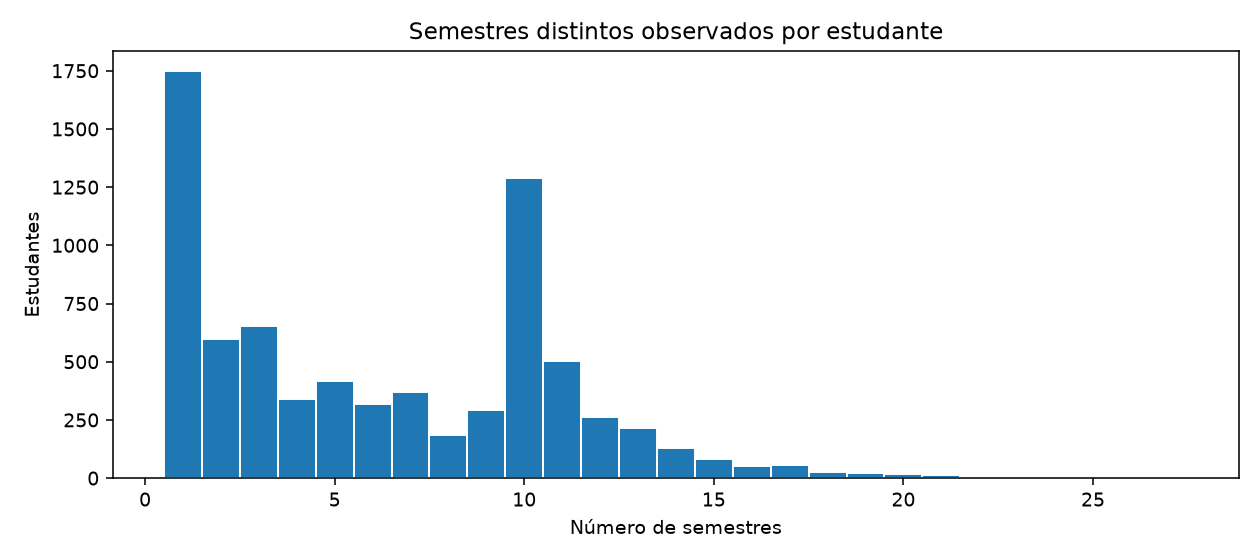

In [4]:
semestres_por_aluno = df.groupby("HANDLEALUNO").SEM.nunique()
mostrar("Semestres observados por aluno", semestres_por_aluno.describe().to_frame("semestres"))
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(
    semestres_por_aluno,
    bins=np.arange(0.5, semestres_por_aluno.max() + 1.5),
    edgecolor="white"
)
ax.set(title="Semestres distintos observados por estudante", xlabel="Número de semestres", ylabel="Estudantes")
finalizar_figura(fig, "02_semestres_por_estudante")


### Como interpretar a cobertura

Ingresso, lacunas e o fim da extração limitam o número de semestres observados. Alunos acompanhados por períodos diferentes não têm a mesma oportunidade de apresentar uma saída.


## 3. Quem está representado na base? — distribuição por curso

Contamos estudantes distintos em cada sigla registrada. Um aluno pode ter passado por mais de um curso; as categorias se sobrepõem e a soma não corresponde ao total de pessoas da base.


,estudantes
SIGLACURSO,
GEC,2041
GET,1570
GEA,1196
GES,1034
GEB,930
TAI,604
GEE,490
TGT,285
GEP,282


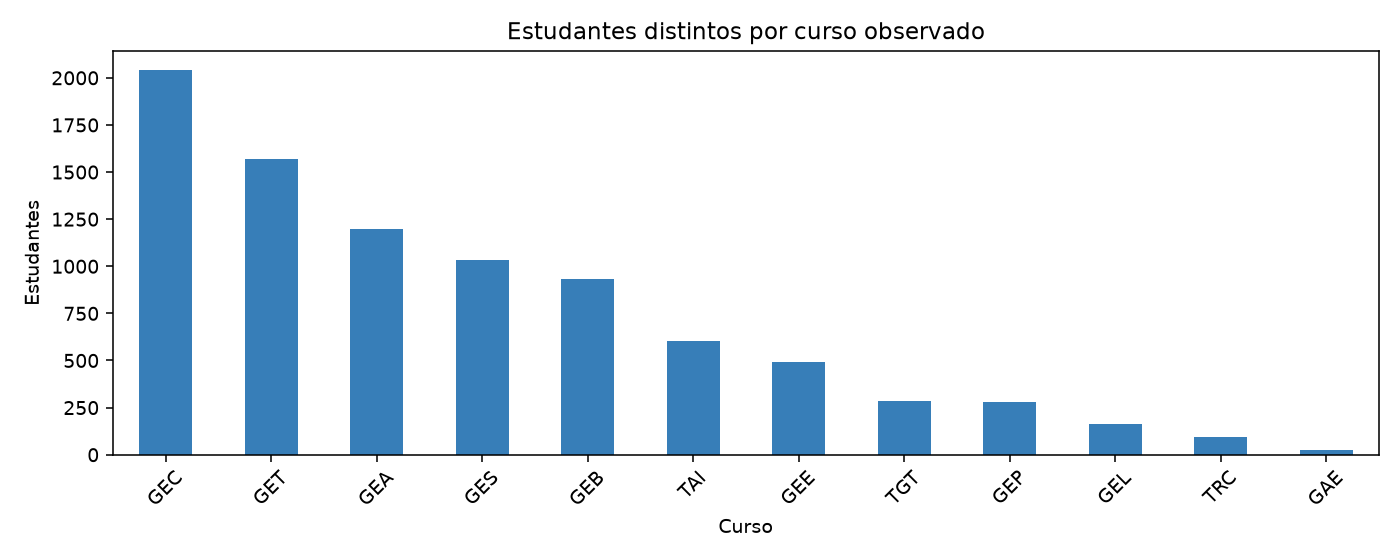

In [5]:
cursos = df.groupby("SIGLACURSO").HANDLEALUNO.nunique().sort_values(ascending=False)
mostrar("Estudantes por curso", cursos.to_frame("estudantes"))
fig, ax = plt.subplots(figsize=(10, 4))
cursos.plot.bar(ax=ax, color="#377eb8")
ax.set(title="Estudantes distintos por curso observado", xlabel="Curso", ylabel="Estudantes")
ax.tick_params(axis="x", rotation=45)
finalizar_figura(fig, "03_estudantes_por_curso")


## 4. Quantos estudantes apresentam eventos de saída?

Consideramos desistência, abandono, cancelamento e desligamento. Transferência/afastamento, trancamento e conclusão ficam separados. Para contar semestres com eventos, unimos os flags do mesmo aluno/semestre: algum positivo é “sim”; todos conhecidos e zero são “não”; ausência sem positivo permanece indefinida.


In [6]:
EVENTOS_SAIDA_PRINCIPAIS = [
    "TEVEDESISTENCIA", "TEVEABANDONO", "TEVECANCELAMENTO", "TEVEDESLIGAMENTO"
]
EVENTOS_CONCLUSAO = ["TEVEDIPLOMACAO", "TEVECONCLUSAOPROGRAMA"]
CHAVE = ["HANDLEALUNO", "SEM"]


def combinar_flags(frame, colunas):
    positivo = frame[colunas].eq(1).any(axis=1)
    conhecido = frame[colunas].notna().all(axis=1)
    return pd.Series(
        np.where(positivo, 1, np.where(conhecido, 0, np.nan)),
        index=frame.index
    )


df["EVENTO_SAIDA"] = combinar_flags(df, EVENTOS_SAIDA_PRINCIPAIS)
df["CONCLUSAO"] = combinar_flags(df, EVENTOS_CONCLUSAO)
colunas_eventos = FLAGS + ["EVENTO_SAIDA", "CONCLUSAO"]
agrupados = df.groupby(CHAVE)
maximos = agrupados[colunas_eventos].max()
conhecidos = agrupados[colunas_eventos].count()
eventos_semestre = maximos.where(
    maximos.eq(1) | conhecidos.eq(agrupados.size(), axis=0)
).reset_index()
primeira_saida = eventos_semestre.loc[eventos_semestre.EVENTO_SAIDA.eq(1)].groupby("HANDLEALUNO").SEM.min()
ultima_saida = eventos_semestre.loc[eventos_semestre.EVENTO_SAIDA.eq(1)].groupby("HANDLEALUNO").SEM.max()
primeira_conclusao = eventos_semestre.loc[eventos_semestre.CONCLUSAO.eq(1)].groupby("HANDLEALUNO").SEM.min()
alunos_saida = primeira_saida.index
alunos_sem_saida = pd.Index(df.HANDLEALUNO.unique()).difference(alunos_saida)
df["PRIMEIRA_SAIDA"] = df.HANDLEALUNO.map(primeira_saida)
eventos_semestre["PRIMEIRA_SAIDA"] = eventos_semestre.HANDLEALUNO.map(primeira_saida)

resumo_saida = pd.DataFrame([{
    "alunos_com_saida": len(alunos_saida),
    "linhas_positivas": int(df.EVENTO_SAIDA.eq(1).sum()),
    "alunos_semestres_positivos": int(eventos_semestre.EVENTO_SAIDA.eq(1).sum()),
    "alunos_com_transferência_afastamento": eventos_semestre.loc[
        eventos_semestre.TEVETRANSAFASTAMENTO.eq(1), "HANDLEALUNO"
    ].nunique()
}])
mostrar("Eventos de saída", resumo_saida)


,alunos_com_saida,linhas_positivas,alunos_semestres_positivos,alunos_com_transferência_afastamento
0,3507,3841,3728,323


### Eventos não são episódios independentes

O número de alunos com saída não é o número de evadidos definitivos. Sem identificador e data da ocorrência, linhas positivas e semestres positivos também não determinam quantos episódios independentes ocorreram.


## 5. Como as saídas são registradas na instituição?

Cada tipo de flag é contado em três unidades: linhas positivas, alunos/semestres positivos e estudantes distintos. Os tipos podem se sobrepor.


,evento,linhas_positivas,alunos_semestres,estudantes
0,Desistência,2313,2267,2184
1,Abandono,761,700,659
2,Cancelamento,766,765,756
3,Desligamento,1,1,1


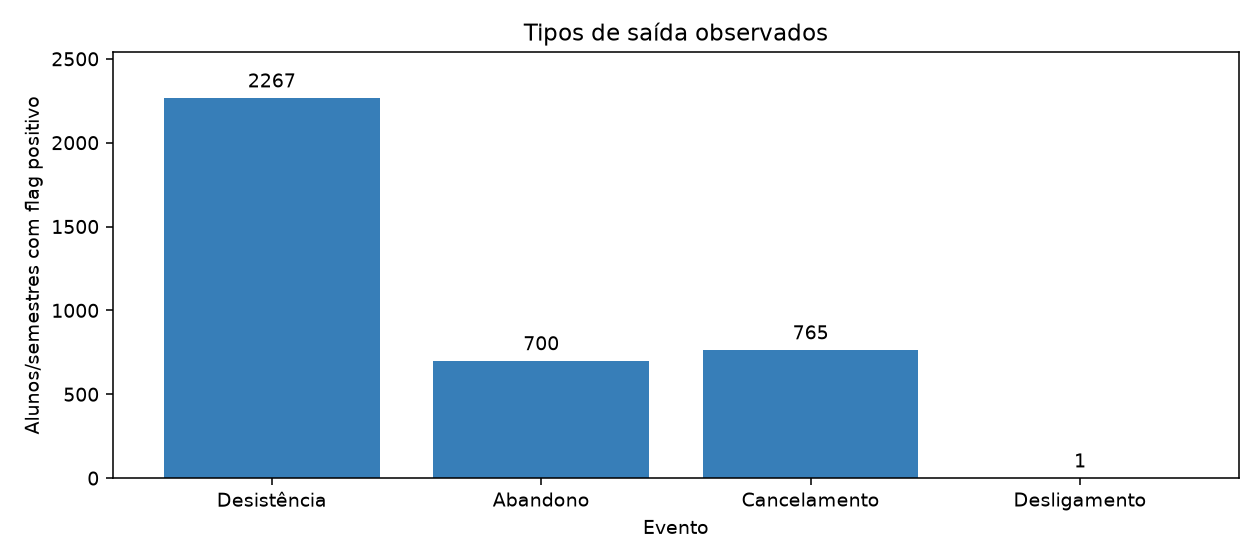

In [7]:
nomes_eventos = ["Desistência", "Abandono", "Cancelamento", "Desligamento"]
eventos = pd.DataFrame([
    {
        "evento": nome,
        "linhas_positivas": int(df[coluna].eq(1).sum()),
        "alunos_semestres": int(eventos_semestre[coluna].eq(1).sum()),
        "estudantes": eventos_semestre.loc[eventos_semestre[coluna].eq(1), "HANDLEALUNO"].nunique()
    }
    for nome, coluna in zip(nomes_eventos, EVENTOS_SAIDA_PRINCIPAIS)
])
mostrar("Tipos de saída", eventos)
fig, ax = plt.subplots(figsize=(9, 4))
barras = ax.bar(eventos.evento, eventos.alunos_semestres, color="#377eb8")
ax.bar_label(barras, padding=3)
ax.margins(y=0.12)
ax.set(title="Tipos de saída observados", ylabel="Alunos/semestres com flag positivo", xlabel="Evento")
finalizar_figura(fig, "05_tipos_de_saida")


## 6. Em que momentos da série histórica os eventos de saída aparecem?

A série conta estudantes com flag positivo em cada semestre, incluindo saídas posteriores à primeira. Picos também podem refletir cobertura e procedimentos administrativos; o gráfico não fornece uma taxa de evasão.


,semestre,estudantes
0,2009/1,26
1,2009/2,27
2,2010/1,57
3,2010/2,58
4,2011/1,111
5,2011/2,82
6,2012/1,97
7,2012/2,127
8,2013/1,191
9,2013/2,127


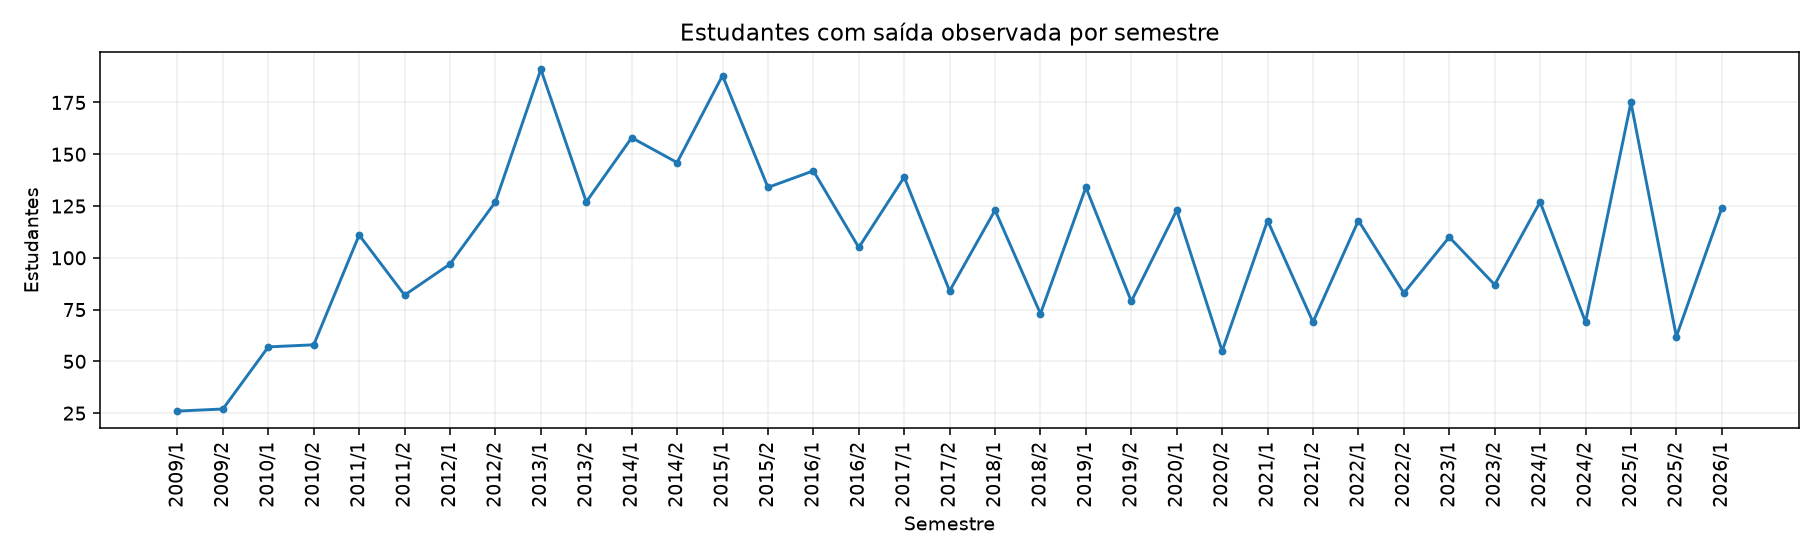

In [8]:
saidas_semestre = (
    eventos_semestre.loc[eventos_semestre.EVENTO_SAIDA.eq(1)]
    .groupby("SEM").HANDLEALUNO.nunique()
    .reindex(sorted(df.SEM.unique()), fill_value=0)
)
mostrar("Saídas por semestre", saidas_semestre.rename_axis("ordinal").reset_index(name="estudantes").assign(
    semestre=lambda tabela: tabela.ordinal.map(rotulo_semestre)
)[["semestre", "estudantes"]])
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(range(len(saidas_semestre)), saidas_semestre.values, marker="o", markersize=3)
ax.set_xticks(range(len(saidas_semestre)), [rotulo_semestre(s) for s in saidas_semestre.index], rotation=90)
ax.set(title="Estudantes com saída observada por semestre", xlabel="Semestre", ylabel="Estudantes")
ax.grid(alpha=0.2)
finalizar_figura(fig, "06_saidas_no_calendario")


## 7. O comportamento dos eventos de saída é parecido entre os cursos?

O denominador é o conjunto de estudantes que aparecem no curso; o numerador conta os que têm um flag de saída em registro associado àquela sigla. Isso descreve a extração, sem equiparar saída de um vínculo à evasão da instituição. Os cursos têm tempos de acompanhamento diferentes.


,estudantes,com_evento_saida,proporcao_com_evento_%
SIGLACURSO,,,
TRC,96,60,62.500
TGT,285,173,60.702
TAI,604,344,56.954
GEB,930,450,48.387
GEL,163,77,47.239
GEP,282,116,41.135
GEC,2041,834,40.862
GET,1570,618,39.363
GEE,490,189,38.571


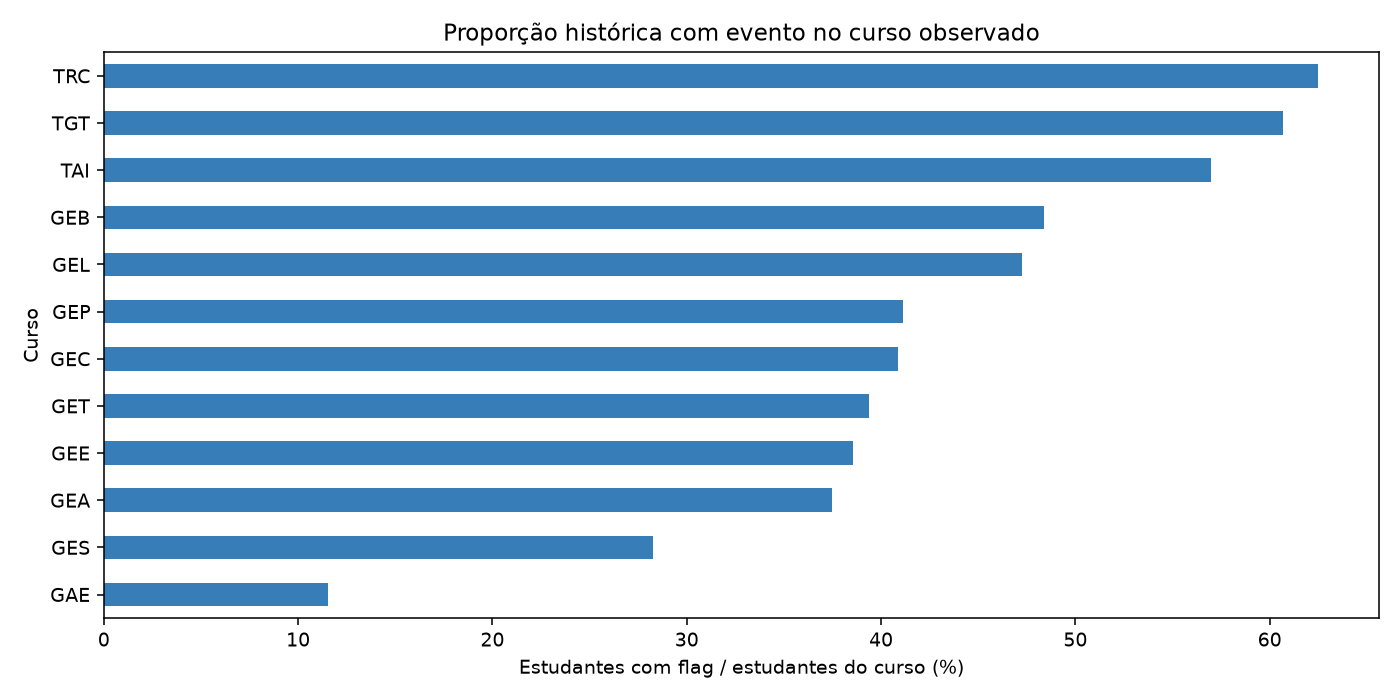

In [9]:
pop_curso = df.groupby("SIGLACURSO").HANDLEALUNO.nunique()
saida_curso = df.loc[df.EVENTO_SAIDA.eq(1)].groupby("SIGLACURSO").HANDLEALUNO.nunique()
curso_saida = pop_curso.rename("estudantes").to_frame()
curso_saida["com_evento_saida"] = saida_curso.reindex(pop_curso.index, fill_value=0)
curso_saida["proporcao_com_evento_%"] = curso_saida.com_evento_saida / curso_saida.estudantes * 100
curso_saida = curso_saida.sort_values("proporcao_com_evento_%", ascending=False)
mostrar("Saídas por curso observado", curso_saida)
fig, ax = plt.subplots(figsize=(10, 5))
curso_saida["proporcao_com_evento_%"].sort_values().plot.barh(ax=ax, color="#377eb8")
ax.set(title="Proporção histórica com evento no curso observado", xlabel="Estudantes com flag / estudantes do curso (%)", ylabel="Curso")
finalizar_figura(fig, "07_proporcao_por_curso")


### Como interpretar a comparação

As proporções são cumulativas na janela observada, com alunos compartilhados entre cursos. Não estabelecem um ranking de taxas institucionais de evasão.


## 8. A composição por sexo é diferente entre os grupos?

Usamos uma categoria de sexo por estudante quando o cadastro é consistente, deixando ausência e conflito separados. Comparamos a proporção com qualquer saída principal durante a janela. O qui-quadrado, quando seus pressupostos de contagem são atendidos, descreve associação bruta sem ajustar diferenças de seguimento.


,estudantes,com_saida,proporcao_com_saida_%
sexo,,,
F,1680,698,41.548
M,5928,2806,47.335
Sem informação,7,3,42.857


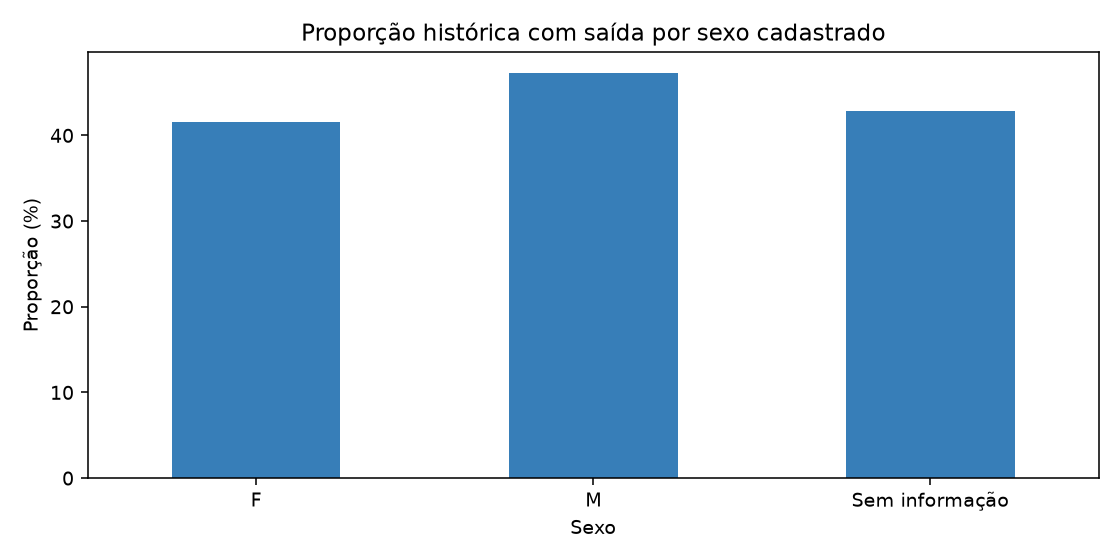

,n_estudantes,chi_quadrado,p_valor,graus_liberdade,menor_contagem_esperada,pressuposto_contagem_atendido
0,7608,17.413,0.000,1,773.754,True


p-valor do teste exploratório: 3.01e-05


In [10]:
def categoria_consistente(serie):
    valores = serie.dropna().unique()
    if serie.isna().any() or len(valores) == 0:
        return "Sem informação"
    if len(valores) > 1:
        return "Cadastro conflitante"
    return valores[0]


sexo_aluno = df.groupby("HANDLEALUNO").SEXO.agg(categoria_consistente)
sexo_evento = pd.DataFrame({"sexo": sexo_aluno, "com_saida": sexo_aluno.index.isin(alunos_saida)})
sexo = sexo_evento.groupby("sexo").com_saida.agg(estudantes="size", com_saida="sum")
sexo["proporcao_com_saida_%"] = sexo.com_saida / sexo.estudantes * 100
mostrar("Sexo e saída observada", sexo)
fig, ax = plt.subplots(figsize=(8, 4))
sexo["proporcao_com_saida_%"].plot.bar(ax=ax, color="#377eb8")
ax.set(title="Proporção histórica com saída por sexo cadastrado", xlabel="Sexo", ylabel="Proporção (%)")
ax.tick_params(axis="x", rotation=0)
finalizar_figura(fig, "08_proporcao_por_sexo")

sexo_conhecido = sexo_evento.loc[sexo_evento.sexo.isin(["M", "F"])]
tabela_sexo = pd.crosstab(sexo_conhecido.sexo, sexo_conhecido.com_saida)
chi2, p_valor, graus, esperados = chi2_contingency(tabela_sexo)
teste_sexo = pd.DataFrame([{
    "n_estudantes": len(sexo_conhecido),
    "chi_quadrado": chi2,
    "p_valor": p_valor if (esperados >= 5).all() else np.nan,
    "graus_liberdade": graus,
    "menor_contagem_esperada": esperados.min(),
    "pressuposto_contagem_atendido": bool((esperados >= 5).all())
}])
mostrar("Qui-quadrado exploratório — sexo conhecido", teste_sexo)
print(f"p-valor do teste exploratório: {p_valor:.3g}" if (esperados >= 5).all() else "Teste suspenso por contagem esperada insuficiente.")


### E o turno?

Contamos estudantes e flags associados a cada turno observado. Um aluno pode aparecer nos dois turnos; os grupos não são independentes nem categorias permanentes da pessoa. A comparação é descritiva, sem teste entre essas populações sobrepostas.


,estudantes,com_saida,proporcao_com_saida_%
TURNO,,,
Integral,5774,2405,41.652
Noturno,2666,1164,43.661


Estudantes observados em mais de um turno: 825


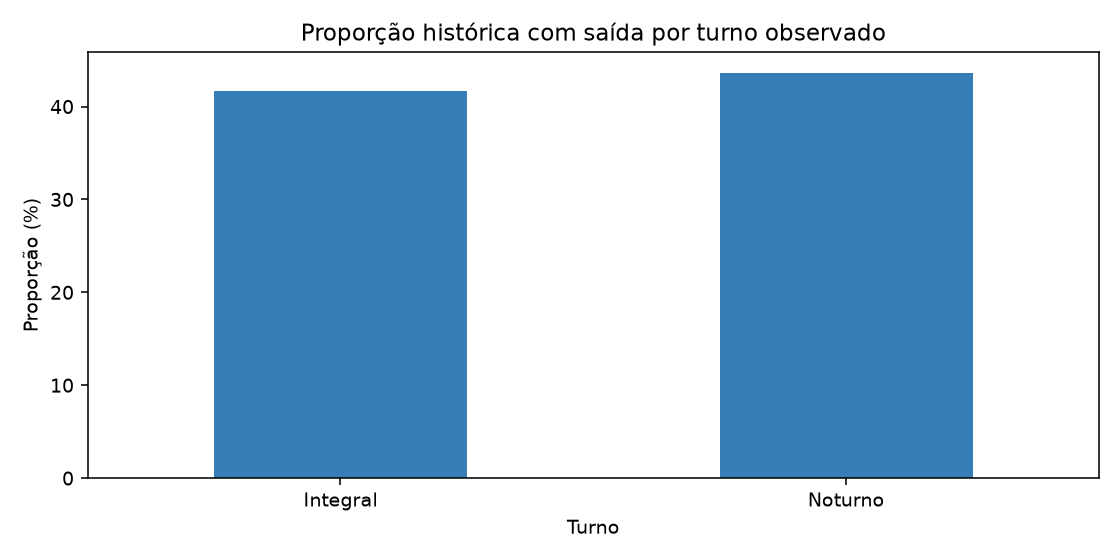

In [11]:
turno_pop = df.groupby("TURNO").HANDLEALUNO.nunique()
turno_saida = df.loc[df.EVENTO_SAIDA.eq(1)].groupby("TURNO").HANDLEALUNO.nunique()
turno = turno_pop.rename("estudantes").to_frame()
turno["com_saida"] = turno_saida.reindex(turno.index, fill_value=0)
turno["proporcao_com_saida_%"] = turno.com_saida / turno.estudantes * 100
mostrar("Turno observado e saída", turno)
multiplos_turnos = int(df.groupby("HANDLEALUNO").TURNO.nunique().gt(1).sum())
print(f"Estudantes observados em mais de um turno: {multiplos_turnos}")
fig, ax = plt.subplots(figsize=(8, 4))
turno["proporcao_com_saida_%"].plot.bar(ax=ax, color="#377eb8")
ax.set(title="Proporção histórica com saída por turno observado", xlabel="Turno", ylabel="Proporção (%)")
ax.tick_params(axis="x", rotation=0)
finalizar_figura(fig, "08_proporcao_por_turno")


## 9. O desempenho acadêmico muda antes da saída?

Para cada estudante com saída, procuramos o último semestre com registro `ACADEMICA` **estritamente anterior à primeira saída**. Se o último semestre tiver mais de um registro acadêmico, o retrato permanece ambíguo: não escolhemos por ordem do CSV ou maior identificador. Os eventos continuam preservados.

Os critérios das comparações são:

- **V0 — base descritiva:** casos com primeira saída em `t`, retrato acadêmico único em `t−1` e sem conclusão até `t`. Referências no mesmo semestre, curso e período curricular, Ativo e com matrícula efetivada em `t−1`, sem primeira saída/conclusão até `t`. Uma referência pode sair posteriormente.
- **V1 — elegibilidade equivalente:** acrescenta Ativo e matrícula efetivada em `t−1` também aos casos.
- **V2 — confirmação em t:** mantém V1 e restringe as referências às que têm matrícula acadêmica efetivada em `t`, em qualquer curso. Não confirmação não significa evasão.

Lacunas e estratos sem referência compatível ficam fora das comparações. Cada indicador usa informação disponível nos dois grupos; referências recebem pesos para reproduzir a distribuição dos casos informados nos estratos. As caixas mostram mediana e quartis ponderados, com hastes P5–P95 e sem pontos individuais. Referências são unidades aluno/semestre e podem repetir a mesma pessoa.


In [12]:
academica = df.loc[df.ORIGEMREGISTRO.eq("ACADEMICA")].copy()
pares = df.groupby(CHAVE).agg(
    linhas=("ORIGEMREGISTRO", "size"),
    cursos=("SIGLACURSO", "nunique"),
    vinculos_curriculares=("HANDLEALUNOCURRICULO", "nunique"),
    vinculos_semestrais=("HANDLEALUNOANOSEMESTRE", "nunique")
)
n_academicos = academica.groupby(CHAVE).size().rename("n_academicos")
mostrar("Estrutura dos registros repetidos", pd.DataFrame([{
    "pares_aluno_semestre": len(pares),
    "pares_repetidos": int(pares.linhas.gt(1).sum()),
    "pares_com_vinculos_curriculares_distintos": int(pares.vinculos_curriculares.gt(1).sum()),
    "pares_com_vinculos_semestrais_distintos": int(pares.vinculos_semestrais.gt(1).sum()),
    "pares_com_cursos_distintos": int(pares.cursos.gt(1).sum()),
    "pares_com_multiplos_registros_academicos": int(n_academicos.gt(1).sum())
}]))
academica = academica.join(n_academicos, on=CHAVE)
academica_unica = academica.loc[academica.n_academicos.eq(1)].copy()
anteriores = academica.loc[academica.SEM.lt(academica.PRIMEIRA_SAIDA)]
ultimo_anterior = anteriores.groupby("HANDLEALUNO").SEM.max()
pre_candidatos = anteriores.loc[anteriores.SEM.eq(anteriores.HANDLEALUNO.map(ultimo_anterior))]
df_pre_saida = pre_candidatos.loc[pre_candidatos.n_academicos.eq(1)].copy()
df_pre_saida["LACUNA"] = df_pre_saida.PRIMEIRA_SAIDA - df_pre_saida.SEM
retratos = pd.DataFrame([
    {"situação": "Sem semestre acadêmico anterior", "alunos": len(alunos_saida) - len(ultimo_anterior)},
    {"situação": "Último semestre anterior ambíguo", "alunos": pre_candidatos.loc[pre_candidatos.n_academicos.gt(1), "HANDLEALUNO"].nunique()},
    {"situação": "Semestre imediatamente anterior, único", "alunos": int(df_pre_saida.LACUNA.eq(1).sum())},
    {"situação": "Semestre anterior com lacuna, único", "alunos": int(df_pre_saida.LACUNA.gt(1).sum())}
])
mostrar("Disponibilidade de retratos anteriores", retratos)
assert retratos.alunos.sum() == len(alunos_saida)
assert df_pre_saida.SEM.lt(df_pre_saida.PRIMEIRA_SAIDA).all()
assert not df_pre_saida.HANDLEALUNO.duplicated().any()
assert df_pre_saida.SEM.eq(df_pre_saida.HANDLEALUNO.map(ultimo_anterior)).all()


,pares_aluno_semestre,pares_repetidos,pares_com_vinculos_curriculares_distintos,pares_com_vinculos_semestrais_distintos,pares_com_cursos_distintos,pares_com_multiplos_registros_academicos
0,48200,8825,8825,1104,972,47


,situação,alunos
0,Sem semestre acadêmico anterior,1627
1,Último semestre anterior ambíguo,1
2,"Semestre imediatamente anterior, único",1489
3,"Semestre anterior com lacuna, único",390


### Como montamos o grupo de comparação?

V0 é a referência explícita para as descrições acadêmicas, financeiras e socioeconômicas; V1 e V2 são sensibilidades apresentadas junto ao CRE. Usar o mesmo semestre calendário e período curricular melhora a comparabilidade frente ao último registro de quem nunca teve saída, mas não iguala todas as trajetórias.


In [13]:
ESTRATOS = ["SEM", "SIGLACURSO", "PERIODO_NUM"]
casos_elegiveis = df_pre_saida.loc[df_pre_saida.LACUNA.eq(1)].copy()
casos_elegiveis["CONCLUSAO_INICIAL"] = casos_elegiveis.HANDLEALUNO.map(primeira_conclusao)
casos_elegiveis = casos_elegiveis.loc[
    casos_elegiveis.CONCLUSAO_INICIAL.isna()
    | casos_elegiveis.CONCLUSAO_INICIAL.gt(casos_elegiveis.PRIMEIRA_SAIDA)
]
referencias_elegiveis = academica_unica.copy()
referencias_elegiveis["DESFECHO_T"] = referencias_elegiveis.SEM + 1
referencias_elegiveis["CONCLUSAO_INICIAL"] = referencias_elegiveis.HANDLEALUNO.map(primeira_conclusao)
referencias_elegiveis = referencias_elegiveis.loc[
    referencias_elegiveis.DESFECHO_T.le(df.SEM.max())
    & referencias_elegiveis.STATUSALUNO.eq("Ativo")
    & referencias_elegiveis.MATRICULAEFETIVADA.eq("S")
    & (referencias_elegiveis.PRIMEIRA_SAIDA.isna()
       | referencias_elegiveis.PRIMEIRA_SAIDA.gt(referencias_elegiveis.DESFECHO_T))
    & (referencias_elegiveis.CONCLUSAO_INICIAL.isna()
       | referencias_elegiveis.CONCLUSAO_INICIAL.gt(referencias_elegiveis.DESFECHO_T))
]


def parear(casos, referencias):
    casos = casos.dropna(subset=ESTRATOS).copy()
    referencias = referencias.dropna(subset=ESTRATOS).copy()
    suporte = casos[ESTRATOS].drop_duplicates().merge(
        referencias[ESTRATOS].drop_duplicates(), on=ESTRATOS
    )
    return (
        casos.merge(suporte, on=ESTRATOS, validate="many_to_one"),
        referencias.merge(suporte, on=ESTRATOS, validate="many_to_one"),
        suporte
    )


casos_v0, refs_v0, suporte_v0 = parear(casos_elegiveis, referencias_elegiveis)
mostrar("Amostra V0", pd.DataFrame([{
    "casos_elegíveis_antes_dos_estratos": len(casos_elegiveis),
    "casos_com_referência": len(casos_v0),
    "excluídos_sem_estrato_comum": len(casos_elegiveis) - len(casos_v0),
    "referências_aluno_semestre": len(refs_v0),
    "referências_pessoas": refs_v0.HANDLEALUNO.nunique(),
    "estratos": len(suporte_v0)
}]))


,casos_elegíveis_antes_dos_estratos,casos_com_referência,excluídos_sem_estrato_comum,referências_aluno_semestre,referências_pessoas,estratos
0,1484,1468,16,16697,4933,596


In [14]:
def amostra_comparavel(coluna, casos=None, referencias=None):
    casos = casos_v0 if casos is None else casos
    referencias = refs_v0 if referencias is None else referencias
    a = casos.dropna(subset=[coluna]).copy()
    b = referencias.dropna(subset=[coluna]).copy()
    a[coluna] = a[coluna].astype(float)
    b[coluna] = b[coluna].astype(float)
    contagens = a.groupby(ESTRATOS).size().rename("n_casos").to_frame().join(
        b.groupby(ESTRATOS).size().rename("n_refs"), how="inner"
    ).reset_index()
    a = a.merge(contagens, on=ESTRATOS, validate="many_to_one")
    b = b.merge(contagens, on=ESTRATOS, validate="many_to_one")
    a["PESO"] = 1.0
    b["PESO"] = b.n_casos / b.n_refs
    info = {
        "n_casos": len(a),
        "n_refs_aluno_semestre": len(b),
        "casos_ausentes": int(casos[coluna].isna().sum()),
        "refs_ausentes": int(referencias[coluna].isna().sum()),
        "casos_sem_referência_informada": int(casos[coluna].notna().sum()) - len(a),
        "refs_informadas_fora_suporte": int(referencias[coluna].notna().sum()) - len(b),
        "estratos": len(contagens)
    }
    assert np.isclose(a.PESO.sum(), b.PESO.sum())
    return a, b, info


def comparar(coluna, casos=None, referencias=None):
    a, b, info = amostra_comparavel(coluna, casos, referencias)
    info["indicador"] = coluna
    if len(a) >= MIN_N and len(b) >= MIN_N:
        info["média_casos"] = np.average(a[coluna], weights=a.PESO)
        info["média_refs_padronizada"] = np.average(b[coluna], weights=b.PESO)
    else:
        info["média_casos"] = np.nan
        info["média_refs_padronizada"] = np.nan
    info["diferença"] = info["média_casos"] - info["média_refs_padronizada"]
    return info


def quantis_ponderados(valores, pesos):
    ordem = np.argsort(np.asarray(valores))
    valores = np.asarray(valores)[ordem]
    pesos = np.asarray(pesos)[ordem]
    acumulado = (np.cumsum(pesos) - pesos / 2) / pesos.sum()
    return np.interp([0.05, 0.25, 0.50, 0.75, 0.95], acumulado, valores)


def caixas_comparaveis(colunas, titulos, nome, unidade, symlog=False):
    fig, axes = plt.subplots(1, len(colunas), figsize=(6 * len(colunas), 4.5), squeeze=False)
    for ax, coluna, titulo in zip(axes[0], colunas, titulos):
        a, b, _ = amostra_comparavel(coluna)
        estatisticas = []
        cores_caixas = []
        for grupo, amostra, cor, unidade_n in [
            ("Referências V0", b, COR_REFERENCIAS, "aluno/semestre"),
            ("Antes da saída V0", a, COR_CASOS, "alunos")
        ]:
            if len(amostra) < MIN_N:
                continue
            p5, q1, mediana, q3, p95 = quantis_ponderados(amostra[coluna], amostra.PESO)
            estatisticas.append({
                "label": f"{grupo}\nN={len(amostra)} {unidade_n}",
                "whislo": p5, "q1": q1, "med": mediana,
                "q3": q3, "whishi": p95, "fliers": []
            })
            cores_caixas.append(cor)
        artistas = ax.bxp(estatisticas, showfliers=False, patch_artist=True)
        for caixa, cor in zip(artistas["boxes"], cores_caixas):
            caixa.set_facecolor(cor)
        for mediana in artistas["medians"]:
            mediana.set_color("black")
        ax.set(title=titulo, ylabel=unidade)
        ax.grid(axis="y", alpha=0.2)
        if symlog:
            ax.set_yscale("symlog", linthresh=100)
    fig.text(
        0.5, 0.02,
        "Caixa: quartis P25–P75; linha: mediana; hastes: P5–P95.\n"
        "Referências ponderadas por semestre, curso e período,\n"
        "para reproduzir a distribuição dos casos informados.",
        ha="center", va="bottom", fontsize=8
    )
    finalizar_figura(fig, nome, margem_inferior=0.16)


### A definição de saída está coerente com o status acadêmico?

No grupo sem saída principal, resumimos **todos os status do último semestre observado**. Desconhecido, ausente e conflito ficam explícitos. Inativo não é classificado como evadido, e um status Ativo antigo não comprova permanência atual.


In [15]:
ultima_obs = df.groupby("HANDLEALUNO").SEM.max()
ultimos = df.loc[df.SEM.eq(df.HANDLEALUNO.map(ultima_obs))]


def status_consistente(serie):
    valores = set(serie.dropna())
    if serie.isna().any() or not valores or "Desconhecido" in valores:
        return "Indefinido/desconhecido"
    if len(valores) > 1:
        return "Conflito no último semestre"
    return next(iter(valores))


status_final = ultimos.groupby("HANDLEALUNO").STATUSALUNO.agg(status_consistente)
status_sem_saida = status_final.loc[status_final.index.isin(alunos_sem_saida)].value_counts()
mostrar("Status final observado — sem saída principal", status_sem_saida.rename_axis("status").reset_index(name="alunos"))
alunos_diplomados = eventos_semestre.loc[eventos_semestre.CONCLUSAO.eq(1), "HANDLEALUNO"].unique()
mostrar("Conclusão e saída — contagens podem se sobrepor", pd.DataFrame([{
    "conclusão_observada": len(alunos_diplomados),
    "conclusão_sem_saida_principal": len(set(alunos_diplomados) - set(alunos_saida)),
    "conclusão_antes_ou_no_semestre_da_saida": int(primeira_conclusao.le(primeira_saida).sum()),
    "conclusão_depois_da_primeira_saida": int(primeira_conclusao.gt(primeira_saida).sum())
}]))


,status,alunos
0,Ativo,2863
1,Indefinido/desconhecido,946
2,Inativo,267
3,Conflito no último semestre,15
4,Em Mobilidade Acadêmica,11
5,Matrícula Pendente,6


,conclusão_observada,conclusão_sem_saida_principal,conclusão_antes_ou_no_semestre_da_saida,conclusão_depois_da_primeira_saida
0,2634,2475,17,142


### Situações que precisam de definição

A coexistência de saída, retorno e conclusão exige distinguir vínculos e trajetórias. O desfecho institucional e o intervalo sem retorno necessário para caracterizar evasão continuam pendentes.


## 10. Preparação das variáveis numéricas

A leitura preserva zeros e mantém ausências. Vírgulas decimais são convertidas sem alterar as colunas originais em memória. Valores fora do domínio ficam ausentes somente nas colunas analíticas. CRE usa a escala observada 0–100; frequência, bolsa e financiamento são percentuais. Escolaridade e patrimônio são categorias. As contagens de disciplinas não são convertidas em percentuais.


In [16]:
mostrar("Validação numérica", pd.DataFrame(qualidade_numerica))
dominio_flags = pd.DataFrame([
    {
        "flag": coluna,
        "ausentes_originais": int(raw[coluna].isna().sum()),
        "inválidos_ou_ausentes_analíticos": int(df[coluna].isna().sum())
    }
    for coluna in FLAGS
])
mostrar("Validação de flags", dominio_flags)


,variável,nulos,falhas_conversão,fora_domínio,zeros_explícitos
0,CRENOSEMESTRE,16421,0,0,1194
1,CREATESEMESTRE,14209,0,0,1289
2,MEDIANAATESEMESTRE,16428,0,0,784
3,VALORMENSALIDADE,1623,0,0,0
4,IA04_01,14642,0,2,2137
5,IA04_02,14642,0,0,39005
6,IA10_01,40863,0,0,855
7,IA12_01,56659,0,0,0
8,IA75_01,0,0,0,14666
9,IA75_02,0,0,0,18595


,flag,ausentes_originais,inválidos_ou_ausentes_analíticos
0,TEVEDESISTENCIA,0,0
1,TEVEABANDONO,0,0
2,TEVETRANCAMENTO,0,0
3,TEVECANCELAMENTO,0,0
4,TEVEDESLIGAMENTO,0,0
5,TEVETRANSAFASTAMENTO,0,0
6,TEVEDIPLOMACAO,0,0
7,TEVECONCLUSAOPROGRAMA,0,0
8,TEVEREINGRESSO,0,0
9,TEVEMUDANCACURSO,0,0


## 11. O CRE apresenta um comportamento diferente antes da saída?

Comparamos o CRE de `t−1` nos grupos V0, usando a padronização definida na seção 9. Em seguida verificamos quanto as médias dependem da elegibilidade equivalente e da matrícula confirmada das referências em `t`.


,n_casos,n_refs_aluno_semestre,casos_ausentes,refs_ausentes,casos_sem_referência_informada,refs_informadas_fora_suporte,estratos,indicador,média_casos,média_refs_padronizada,diferença
0,1270,15254,198,0,0,1443,538,CRENOSEMESTRE_NUM,23.669,51.727,-28.058


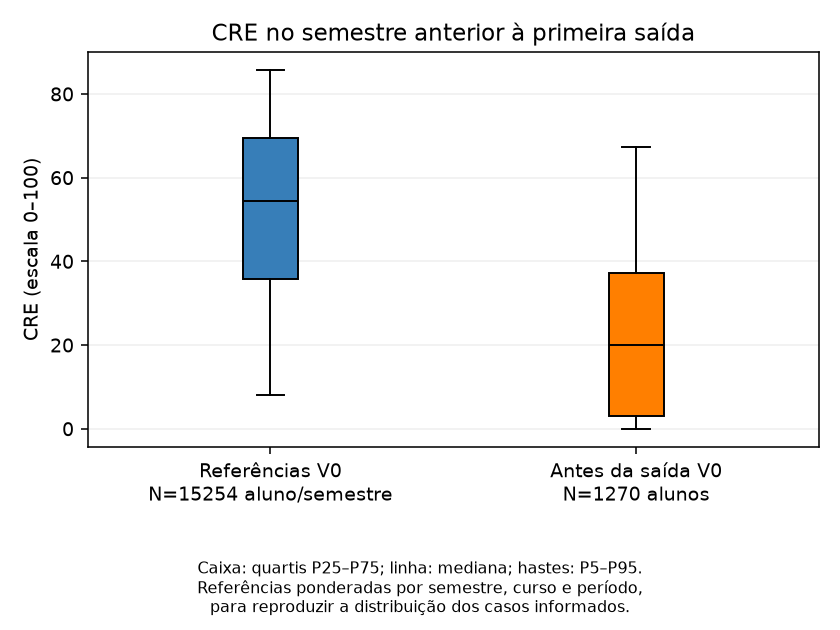

In [17]:
cre_v0 = comparar("CRENOSEMESTRE_NUM")
mostrar("CRE — comparação V0", pd.DataFrame([cre_v0]))
caixas_comparaveis(
    ["CRENOSEMESTRE_NUM"], ["CRE no semestre anterior à primeira saída"],
    "11_cre_v0", "CRE (escala 0–100)"
)


### Quanto a comparação depende da seleção?

V1 exige Ativo e matrícula efetivada em `t−1` nos dois grupos. V2 acrescenta a matrícula acadêmica das referências em `t`. Selecionar pela informação de `t` muda a população de comparação e não demonstra um efeito da permanência sobre o CRE ou a frequência.


,versão,casos,refs_aluno_semestre,refs_pessoas,exclusões_casos_vs_V0
0,V0,1468,16697,4933,0
1,V1,1244,15157,4907,224
2,V2,1244,14729,4834,224


,matrícula_em_t,refs_aluno_semestre
0,Confirmada,14729
1,Não confirmada,428


,status,casos
0,Inativo,205
1,Desconhecido,15
2,Matrícula Pendente,4


,n_casos,n_refs_aluno_semestre,casos_ausentes,refs_ausentes,casos_sem_referência_informada,refs_informadas_fora_suporte,estratos,indicador,média_casos,média_refs_padronizada,diferença,versão
0,1270,15254,198,0,0,1443,538,CRENOSEMESTRE_NUM,23.669,51.727,-28.058,V0
1,1468,16697,0,0,0,0,596,IA04_01_NUM,68.042,90.483,-22.440,V0
2,1243,15157,1,0,0,0,533,CRENOSEMESTRE_NUM,23.820,51.737,-27.917,V1
3,1244,15157,0,0,0,0,533,IA04_01_NUM,78.920,90.566,-11.646,V1
4,1243,14729,1,0,0,0,533,CRENOSEMESTRE_NUM,23.820,52.315,-28.495,V2
5,1244,14729,0,0,0,0,533,IA04_01_NUM,78.920,90.727,-11.807,V2


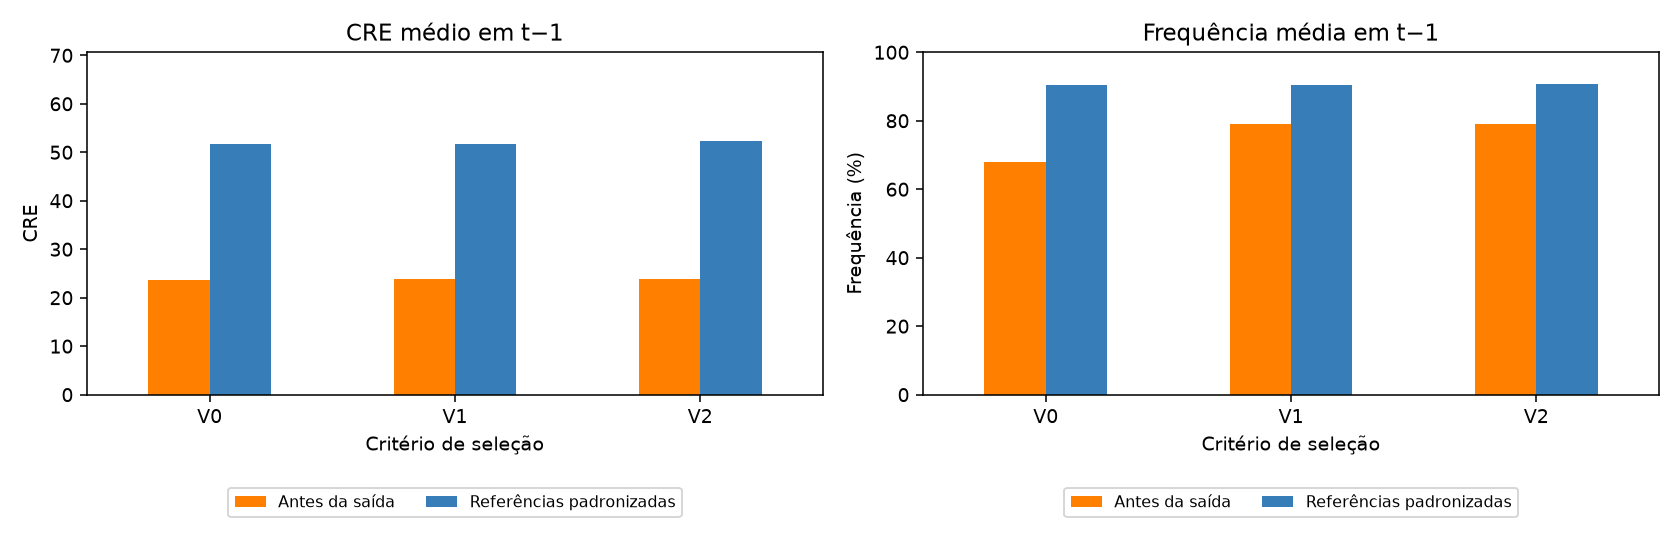

In [18]:
ativo_casos = (
    casos_elegiveis.STATUSALUNO.eq("Ativo")
    & casos_elegiveis.MATRICULAEFETIVADA.eq("S")
).fillna(False)
casos_v1, refs_v1, suporte_v1 = parear(casos_elegiveis.loc[ativo_casos], referencias_elegiveis)
confirmacoes = (
    academica.loc[academica.MATRICULAEFETIVADA.eq("S"), CHAVE]
    .drop_duplicates()
    .rename(columns={"SEM": "DESFECHO_T"})
    .assign(CONFIRMADA_T=True)
)
refs_v1_t = refs_v1.merge(confirmacoes, on=["HANDLEALUNO", "DESFECHO_T"], how="left", validate="many_to_one")
refs_v1_t["CONFIRMADA_T"] = refs_v1_t.CONFIRMADA_T.eq(True)
casos_v2, refs_v2, suporte_v2 = parear(casos_v1, refs_v1_t.loc[refs_v1_t.CONFIRMADA_T])
grupos_comparacao = {
    "V0": (casos_v0, refs_v0),
    "V1": (casos_v1, refs_v1),
    "V2": (casos_v2, refs_v2)
}
mostrar("Amostras das sensibilidades", pd.DataFrame([
    {
        "versão": versao,
        "casos": len(casos),
        "refs_aluno_semestre": len(referencias),
        "refs_pessoas": referencias.HANDLEALUNO.nunique(),
        "exclusões_casos_vs_V0": len(casos_v0) - len(casos)
    }
    for versao, (casos, referencias) in grupos_comparacao.items()
]))
mostrar("Referências V1 por matrícula em t", pd.DataFrame([
    {"matrícula_em_t": nome, "refs_aluno_semestre": int(mascara.sum())}
    for nome, mascara in [
        ("Confirmada", refs_v1_t.CONFIRMADA_T),
        ("Não confirmada", ~refs_v1_t.CONFIRMADA_T)
    ]
]))
mostrar("Casos V0 excluídos pela elegibilidade de V1", casos_v0.loc[
    ~casos_v0.HANDLEALUNO.isin(casos_v1.HANDLEALUNO), "STATUSALUNO"
].value_counts(dropna=False).rename_axis("status").reset_index(name="casos"))
sensibilidades = pd.DataFrame([
    dict(comparar(coluna, casos, referencias), versão=versao)
    for versao, (casos, referencias) in grupos_comparacao.items()
    for coluna in ["CRENOSEMESTRE_NUM", "IA04_01_NUM"]
])
mostrar("CRE e frequência — sensibilidades", sensibilidades)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, coluna, titulo, unidade in zip(
    axes, ["CRENOSEMESTRE_NUM", "IA04_01_NUM"],
    ["CRE médio em t−1", "Frequência média em t−1"], ["CRE", "Frequência (%)"]
):
    tabela = sensibilidades.loc[sensibilidades.indicador.eq(coluna)].set_index("versão")
    tabela[["média_casos", "média_refs_padronizada"]].rename(columns={
        "média_casos": "Antes da saída", "média_refs_padronizada": "Referências padronizadas"
    }).plot.bar(ax=ax, color=[COR_CASOS, COR_REFERENCIAS])
    ax.set(title=titulo, ylabel=unidade, xlabel="Critério de seleção")
    ax.tick_params(axis="x", rotation=0)
    ax.margins(y=0.35)
    if coluna == "IA04_01_NUM":
        ax.set_ylim(0, 100)
    ax.legend(
        fontsize=8, loc="upper center",
        bbox_to_anchor=(0.5, -0.25), ncol=2
    )
finalizar_figura(fig, "11_sensibilidades_cre_frequencia")


## 12. O CRE sozinho conta toda a história?

As variáveis `IA75_03` e `IA34_03` registram **quantidades** de disciplinas. Há contagens acima de `IA75_04`, número de matriculadas, inclusive em linhas acadêmicas. Mostramos as contagens registradas com a janela ainda pendente; os percentuais de aprovação/reprovação ficam suspensos até confirmar o SQL e o tratamento de aproveitamentos e mudanças curriculares.


,origem,linhas,aprovadas_maiores_que_matriculadas,reprovadas_maiores_que_matriculadas
0,ACADEMICA,44417,5388,138
1,OCORRENCIA,14642,0,0


,n_casos,n_refs_aluno_semestre,casos_ausentes,refs_ausentes,casos_sem_referência_informada,refs_informadas_fora_suporte,estratos,indicador,média_casos,média_refs_padronizada,diferença
0,1468,16697,0,0,0,0,596,IA75_03_NUM,2.296,4.927,-2.631
1,1468,16697,0,0,0,0,596,IA34_03_NUM,3.282,1.593,1.689
2,1468,16697,0,0,0,0,596,IA75_04_NUM,5.858,5.937,-0.079
3,1468,16697,0,0,0,0,596,IA65_03_NUM,0.426,0.374,0.051


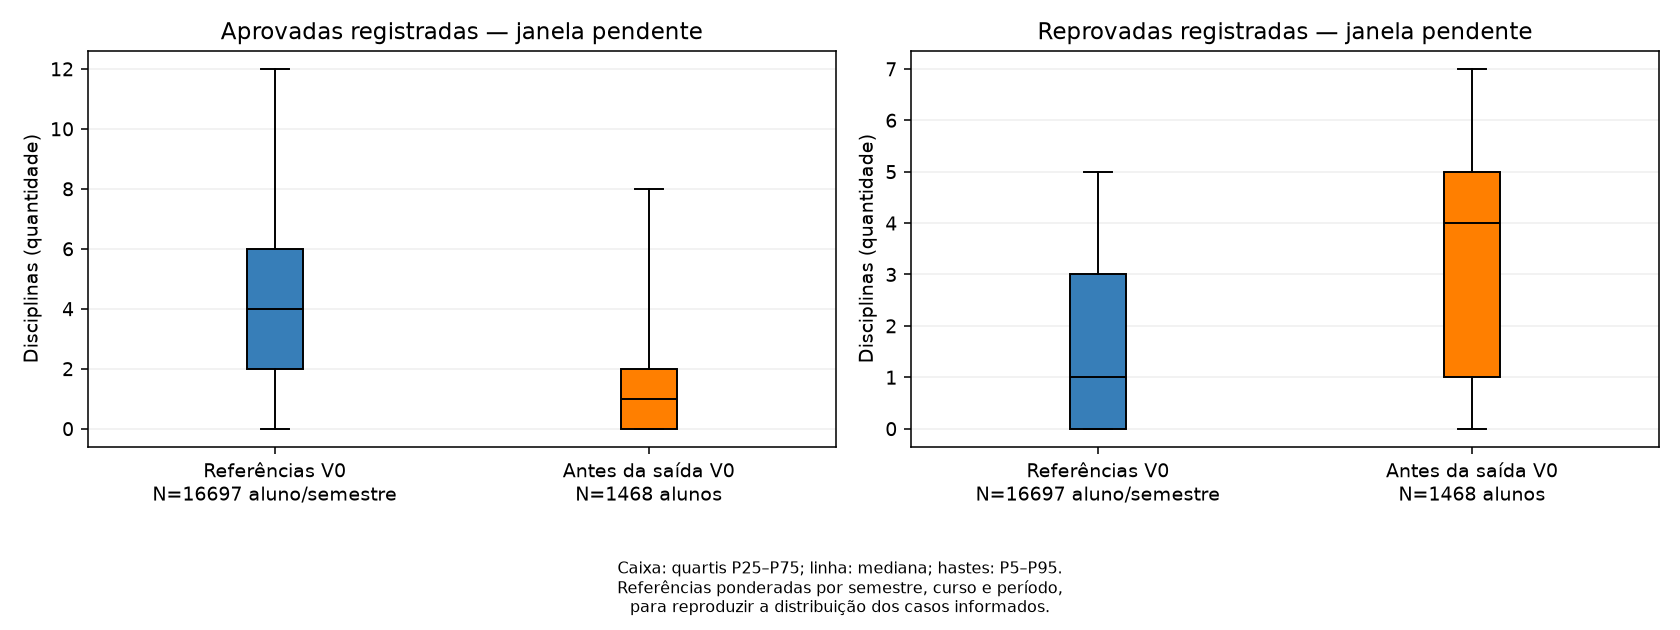

In [19]:
inconsistencias_contagens = pd.DataFrame([
    {
        "origem": origem,
        "linhas": len(grupo),
        "aprovadas_maiores_que_matriculadas": int(grupo.IA75_03_NUM.gt(grupo.IA75_04_NUM).sum()),
        "reprovadas_maiores_que_matriculadas": int(grupo.IA34_03_NUM.gt(grupo.IA75_04_NUM).sum())
    }
    for origem, grupo in df.groupby("ORIGEMREGISTRO")
])
mostrar("Janelas de contagem pendentes", inconsistencias_contagens)
desempenho = pd.DataFrame([
    comparar(coluna) for coluna in ["IA75_03_NUM", "IA34_03_NUM", "IA75_04_NUM", "IA65_03_NUM"]
])
mostrar("Contagens registradas — V0", desempenho)
caixas_comparaveis(
    ["IA75_03_NUM", "IA34_03_NUM"],
    ["Aprovadas registradas — janela pendente", "Reprovadas registradas — janela pendente"],
    "12_contagens_desempenho", "Disciplinas (quantidade)"
)


## 13. A frequência também apresenta diferença antes da saída?

`IA04_01` é o percentual de frequência do semestre. A comparação V0 usa apenas o retrato acadêmico de `t−1`, com valores entre 0 e 100. As alternativas de elegibilidade foram apresentadas junto ao CRE, na seção 11.


,n_casos,n_refs_aluno_semestre,casos_ausentes,refs_ausentes,casos_sem_referência_informada,refs_informadas_fora_suporte,estratos,indicador,média_casos,média_refs_padronizada,diferença
0,1468,16697,0,0,0,0,596,IA04_01_NUM,68.042,90.483,-22.440


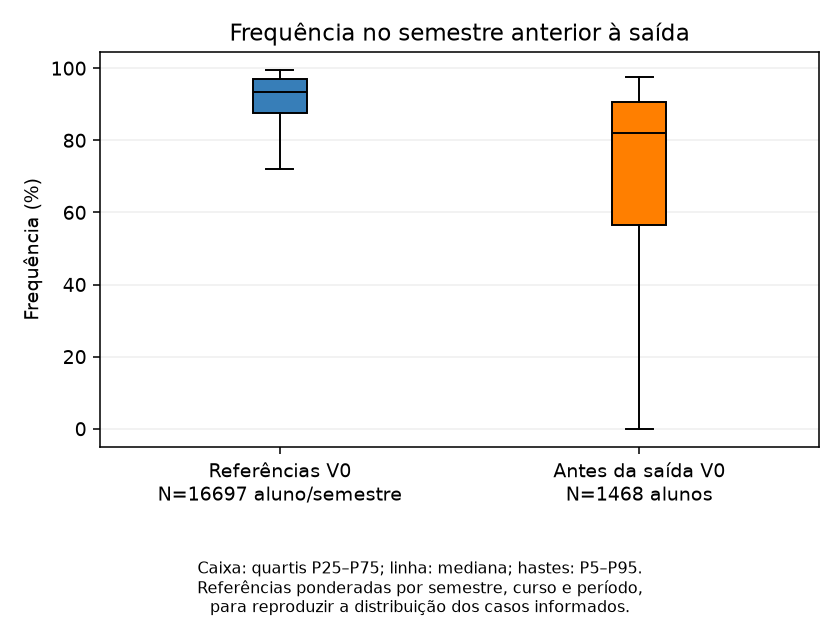

In [20]:
frequencia_v0 = comparar("IA04_01_NUM")
mostrar("Frequência — V0", pd.DataFrame([frequencia_v0]))
caixas_comparaveis(
    ["IA04_01_NUM"], ["Frequência no semestre anterior à saída"],
    "13_frequencia", "Frequência (%)"
)


### E as faltas estão concentradas em algumas disciplinas?

`IA04_02` conta disciplinas com mais de 25% de faltas. Além da quantidade média, calculamos a proporção com pelo menos uma disciplina nessa situação, entre os registros informados e com os mesmos pesos de comparação.


In [21]:
for amostra in [casos_v0, refs_v0]:
    amostra["ALGUMA_DISCIPLINA_FALTAS"] = np.where(
        amostra.IA04_02_NUM.notna(), amostra.IA04_02_NUM.gt(0).astype(float), np.nan
    )
faltas_quantidade = comparar("IA04_02_NUM")
faltas_proporcao = comparar("ALGUMA_DISCIPLINA_FALTAS")
mostrar("Quantidade de disciplinas com excesso de faltas", pd.DataFrame([faltas_quantidade]))
mostrar("Pelo menos uma disciplina com excesso de faltas", pd.DataFrame([{
    "casos_informados": faltas_proporcao["n_casos"],
    "refs_informadas_aluno_semestre": faltas_proporcao["n_refs_aluno_semestre"],
    "casos_%": faltas_proporcao["média_casos"] * 100,
    "refs_padronizadas_%": faltas_proporcao["média_refs_padronizada"] * 100
}]))


,n_casos,n_refs_aluno_semestre,casos_ausentes,refs_ausentes,casos_sem_referência_informada,refs_informadas_fora_suporte,estratos,indicador,média_casos,média_refs_padronizada,diferença
0,1468,16697,0,0,0,0,596,IA04_02_NUM,1.004,0.236,0.768


,casos_informados,refs_informadas_aluno_semestre,casos_%,refs_padronizadas_%
0,1468,16697,37.807,13.017


## 14. O trancamento aparece antes das saídas?

Trancamento não é sinônimo de evasão. Para casos e referências V0, procuramos flags de trancamento em semestres **estritamente anteriores a t**, incluindo `t−1`. O histórico observado tem duração diferente entre estudantes; um zero conhecido significa ausência de flag nessa janela disponível.


,casos_informados,refs_informadas_aluno_semestre,histórico_casos_%,histórico_refs_padronizado_%
0,1468,16697,16.894,2.365


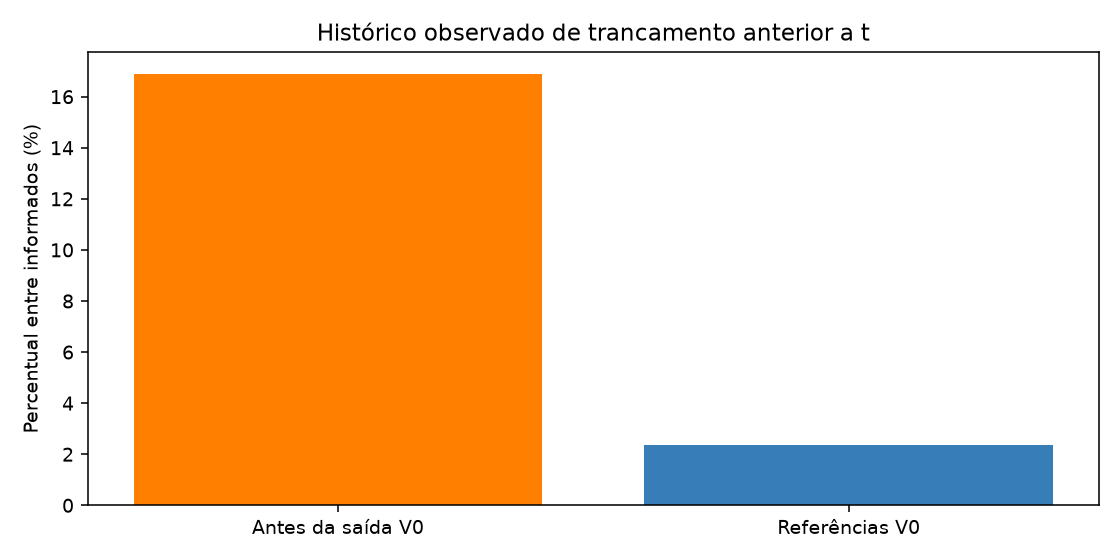

In [22]:
def historico_ate_retrato(amostra, flag):
    historia = eventos_semestre[CHAVE + [flag]].sort_values(CHAVE).copy()
    grupos = historia.groupby("HANDLEALUNO")
    positivos = historia[flag].eq(1).fillna(False).astype(int).groupby(historia.HANDLEALUNO).cumsum().gt(0)
    conhecidos = historia[flag].notna().astype(int).groupby(historia.HANDLEALUNO).cumsum()
    completo = conhecidos.eq(grupos.cumcount() + 1)
    historia["HISTORICO"] = np.where(positivos, 1, np.where(completo, 0, np.nan))
    historia = historia.rename(columns={"SEM": "SEM_EVENTO"})
    ancora = amostra[["HANDLEALUNO", "SEM"]].assign(ORDEM=np.arange(len(amostra)))
    combinado = pd.merge_asof(
        ancora.sort_values("SEM"),
        historia[["HANDLEALUNO", "SEM_EVENTO", "HISTORICO"]].sort_values("SEM_EVENTO"),
        left_on="SEM", right_on="SEM_EVENTO", by="HANDLEALUNO", direction="backward"
    ).sort_values("ORDEM")
    assert combinado.SEM_EVENTO.le(combinado.SEM).all()
    return combinado.HISTORICO.to_numpy()


casos_v0["HIST_TRANCAMENTO"] = historico_ate_retrato(casos_v0, "TEVETRANCAMENTO")
refs_v0["HIST_TRANCAMENTO"] = historico_ate_retrato(refs_v0, "TEVETRANCAMENTO")
trancamento = comparar("HIST_TRANCAMENTO")
trancamento_tabela = pd.DataFrame([{
    "casos_informados": trancamento["n_casos"],
    "refs_informadas_aluno_semestre": trancamento["n_refs_aluno_semestre"],
    "histórico_casos_%": trancamento["média_casos"] * 100,
    "histórico_refs_padronizado_%": trancamento["média_refs_padronizada"] * 100
}])
mostrar("Trancamento anterior a t — V0", trancamento_tabela)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    ["Antes da saída V0", "Referências V0"],
    [trancamento["média_casos"] * 100, trancamento["média_refs_padronizada"] * 100],
    color=[COR_CASOS, COR_REFERENCIAS]
)
ax.set(title="Histórico observado de trancamento anterior a t", ylabel="Percentual entre informados (%)")
finalizar_figura(fig, "14_trancamento_anterior")


## 15. Existe uma dimensão financeira associada às trajetórias de saída?

Usamos bolsa positiva, FIES e perda de FIES no retrato de `t−1`, sem incorporar indicadores de semestres posteriores. Bolsa ausente fica como desconhecida; a proporção é calculada **entre percentuais informados**, não entre todos os alunos. As interpretações dependem do significado dos nulos e da disponibilidade histórica desses indicadores.


,nome,n_casos,n_refs_aluno_semestre,casos_ausentes,refs_ausentes,casos_sem_referência_informada,refs_informadas_fora_suporte,casos_%,refs_padronizadas_%
0,Bolsa positiva entre informados,369,3427,1097,9664,2,3606,96.206,96.629
1,FIES no retrato,1468,16697,0,0,0,0,2.793,5.094
2,Perda de FIES no retrato,1468,16697,0,0,0,0,1.022,0.129


,n_casos,n_refs_aluno_semestre,casos_ausentes,refs_ausentes,casos_sem_referência_informada,refs_informadas_fora_suporte,estratos,indicador,média_casos,média_refs_padronizada,diferença
0,369,3427,1097,9664,2,3606,236,IA10_01_NUM,36.775,38.421,-1.646
1,1421,16171,47,526,0,0,583,VALORMENSALIDADE_NUM,1807.694,1807.694,0.000


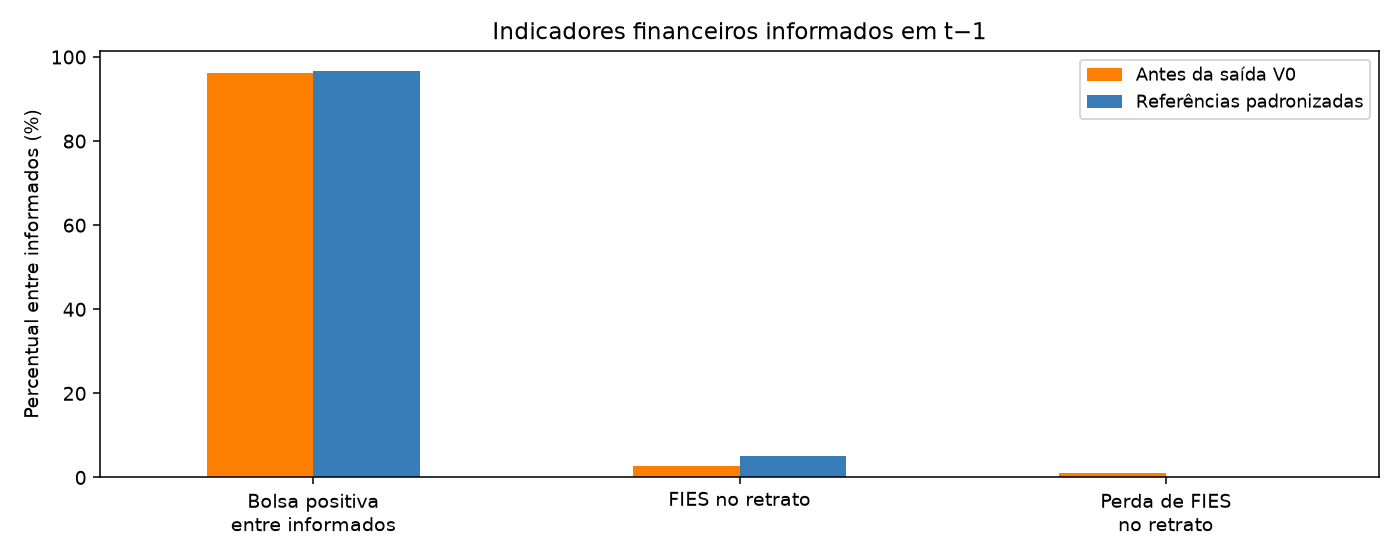

In [23]:
for amostra in [casos_v0, refs_v0]:
    amostra["BOLSA_POSITIVA"] = np.where(
        amostra.IA10_01_NUM.notna(), amostra.IA10_01_NUM.gt(0).astype(float), np.nan
    )
financeiro = pd.DataFrame([
    dict(comparar(coluna), nome=nome)
    for coluna, nome in [
        ("BOLSA_POSITIVA", "Bolsa positiva entre informados"),
        ("IA12", "FIES no retrato"),
        ("IA13", "Perda de FIES no retrato")
    ]
])
financeiro["casos_%"] = financeiro.média_casos * 100
financeiro["refs_padronizadas_%"] = financeiro.média_refs_padronizada * 100
mostrar("Indicadores financeiros em t−1 — V0", financeiro[[
    "nome", "n_casos", "n_refs_aluno_semestre", "casos_ausentes", "refs_ausentes",
    "casos_sem_referência_informada", "refs_informadas_fora_suporte",
    "casos_%", "refs_padronizadas_%"
]])
mostrar("Percentual de bolsa e mensalidade entre informados", pd.DataFrame([
    comparar(coluna) for coluna in ["IA10_01_NUM", "VALORMENSALIDADE_NUM"]
]))
fig, ax = plt.subplots(figsize=(10, 4))
financeiro.set_index("nome")[["casos_%", "refs_padronizadas_%"]].rename(columns={
    "casos_%": "Antes da saída V0", "refs_padronizadas_%": "Referências padronizadas"
}).plot.bar(ax=ax, color=[COR_CASOS, COR_REFERENCIAS])
ax.set(title="Indicadores financeiros informados em t−1", ylabel="Percentual entre informados (%)", xlabel="")
ax.set_xticklabels(["Bolsa positiva\nentre informados", "FIES no retrato", "Perda de FIES\nno retrato"], rotation=0)
ax.legend(fontsize=9)
finalizar_figura(fig, "15_indicadores_financeiros")


## 16. O contexto socioeconômico apresenta diferenças entre os grupos?

Renda, patrimônio e escolaridade descrevem o contexto familiar disponível no retrato de `t−1`. Mantemos também o resumo geral de renda da extração: ele conta linhas, incluindo repetições e registros posteriores. As comparações usam cobertura e distribuições padronizadas em V0. Valores zero são preservados; rendas nominais e declaradas não têm data de coleta/atualização no CSV. A baixa cobertura limita a comparação.


,count,mean,std,25%,50%,75%
IA70_01_NUM,15190.000,4007.687,38682.852,0.000,1200.000,2523.173
IA70_03_NUM,15190.000,1148.867,9214.057,0.000,0.000,1096.343
IA70_05_NUM,15190.000,4013.288,32400.157,0.000,1412.000,3116.185


,n_casos,n_refs_aluno_semestre,casos_ausentes,refs_ausentes,casos_sem_referência_informada,refs_informadas_fora_suporte,estratos,indicador,média_casos,média_refs_padronizada,diferença
0,396,4012,1068,11064,4,1621,254,IA70_01_NUM,2441.233,2847.769,-406.536
1,396,4012,1068,11064,4,1621,254,IA70_03_NUM,907.081,938.843,-31.762
2,396,4012,1068,11064,4,1621,254,IA70_05_NUM,2495.578,3061.735,-566.157


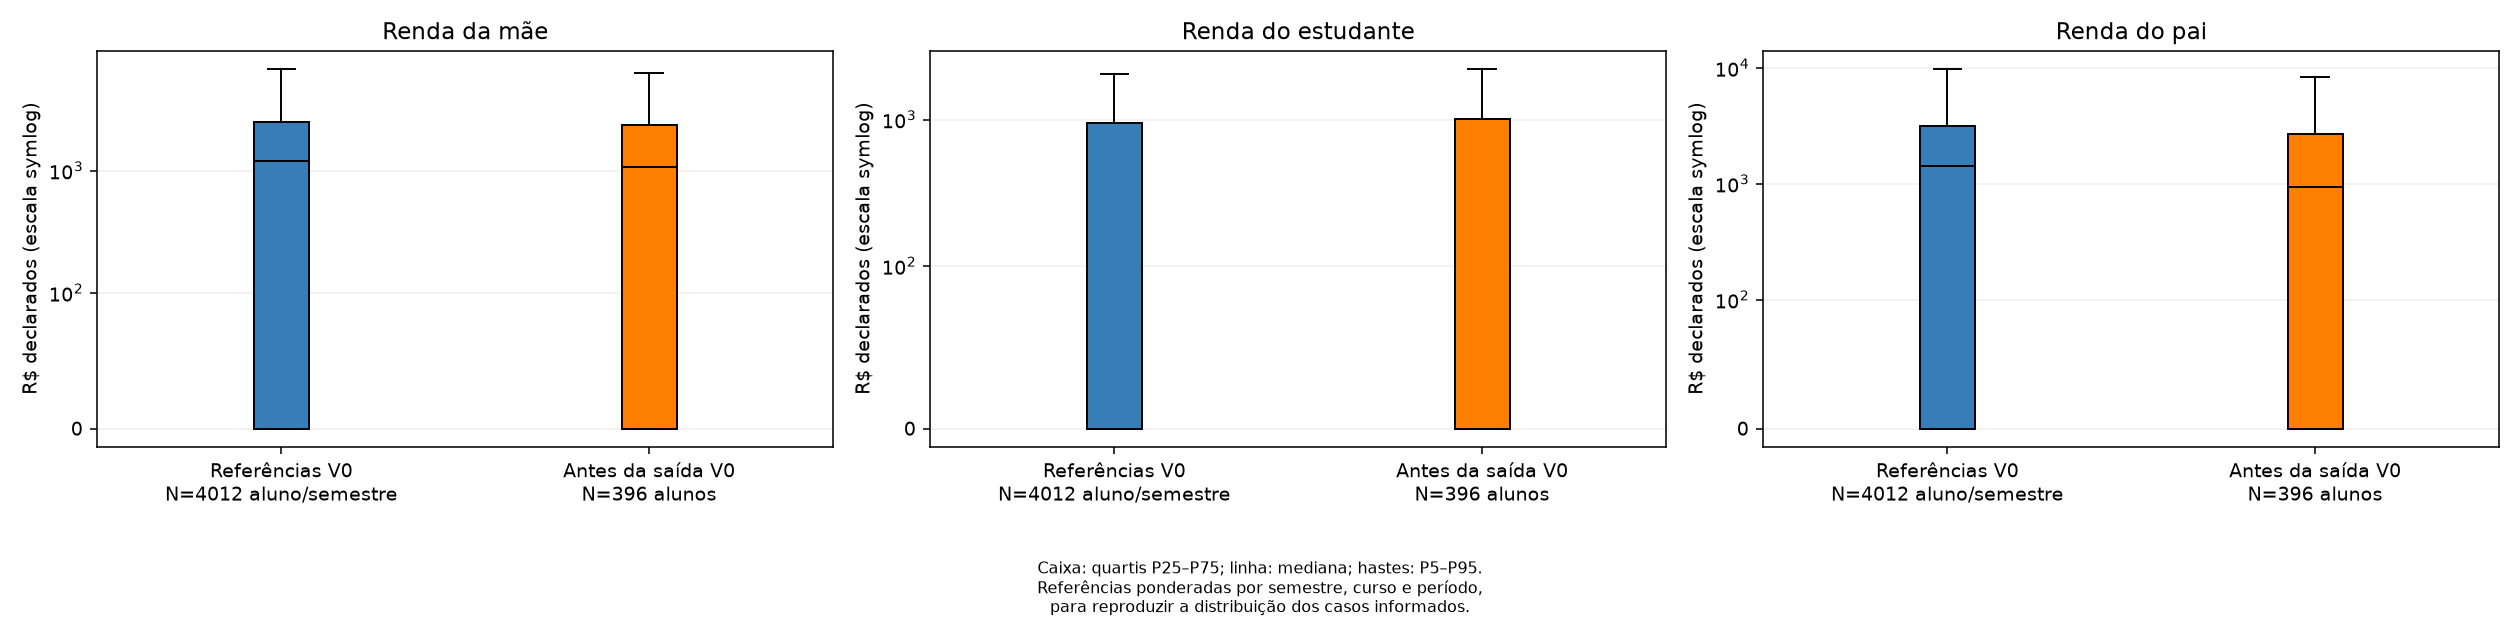

,grupo,variável,total,informados,zeros,ausentes_%
0,Casos V0,IA70_01_NUM,1468,400,144,72.752
1,Casos V0,IA70_03_NUM,1468,400,260,72.752
2,Casos V0,IA70_05_NUM,1468,400,189,72.752
3,Referências V0,IA70_01_NUM,16697,5633,1778,66.263
4,Referências V0,IA70_03_NUM,16697,5633,3670,66.263
5,Referências V0,IA70_05_NUM,16697,5633,1981,66.263


In [24]:
socio_numericas = ["IA70_01_NUM", "IA70_03_NUM", "IA70_05_NUM"]
mostrar(
    "Rendas — descrição geral das linhas da extração",
    df[socio_numericas].describe().loc[["count", "mean", "std", "25%", "50%", "75%"]].T
)
mostrar("Rendas declaradas no retrato — V0", pd.DataFrame([
    comparar(coluna) for coluna in socio_numericas
]))
caixas_comparaveis(
    socio_numericas, ["Renda da mãe", "Renda do estudante", "Renda do pai"],
    "16_rendas", "R$ declarados (escala symlog)", symlog=True
)
mostrar("Cobertura e zeros de renda", pd.DataFrame([
    {
        "grupo": grupo, "variável": coluna, "total": len(amostra),
        "informados": int(amostra[coluna].notna().sum()),
        "zeros": int(amostra[coluna].eq(0).sum()),
        "ausentes_%": amostra[coluna].isna().mean() * 100
    }
    for grupo, amostra in [("Casos V0", casos_v0), ("Referências V0", refs_v0)]
    for coluna in socio_numericas
]))


### Como analisamos o patrimônio familiar

`IA70_04` contém faixas de patrimônio, não um valor contínuo. Comparamos a distribuição de categorias, incluindo ausência e “Não Informado” como **Sem informação**. O denominador inclui todos os retratos de cada grupo; as referências usam os pesos dos casos nos estratos comuns.


,casos_n,casos_%,referências_n,referências_%
categoria,,,,
Sem informação,1173,79.905,11597,71.457
"Até R$ 10.000,00",30,2.044,325,2.229
"R$ 10.000,01 a R$ 30.000,00",20,1.362,221,1.381
"R$ 30.000,01 a R$ 60.000,00",108,7.357,2152,11.902
"R$ 60.000,01 a R$ 150.000,01",55,3.747,996,5.455
"Acima de R$ 150.000,01",82,5.586,1406,7.575


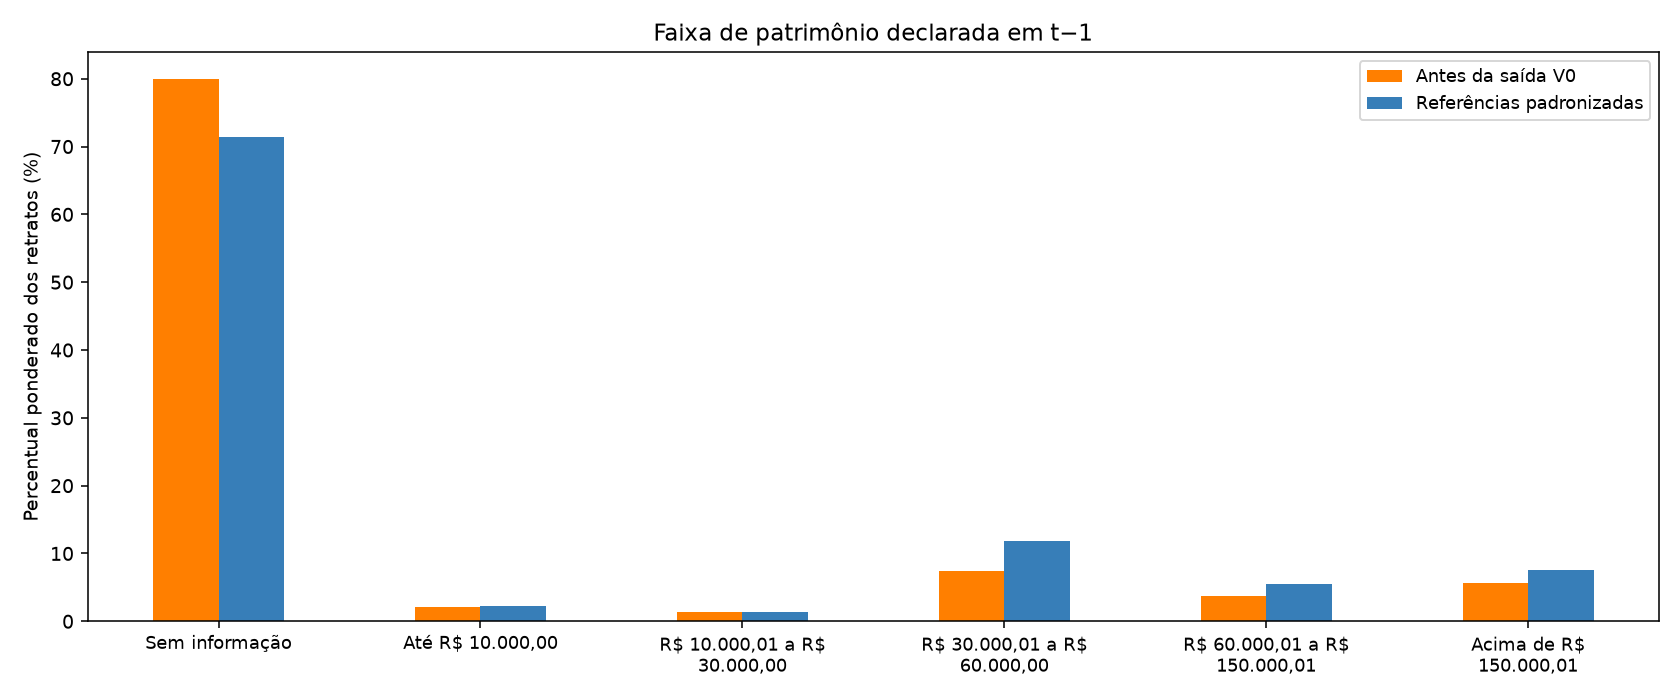

In [25]:
def distribuicao_categorica(coluna, ordem):
    dados_casos = casos_v0.copy()
    dados_refs = refs_v0.copy()
    for amostra in [dados_casos, dados_refs]:
        texto = amostra[coluna].str.strip()
        ausente = texto.isna() | texto.str.lower().isin(TOKENS_AUSENTES)
        amostra["CATEGORIA"] = texto.mask(ausente, "Sem informação")
        amostra["BASE_CATEGORIA"] = 1.0
    a, b, _ = amostra_comparavel("BASE_CATEGORIA", dados_casos, dados_refs)
    observadas = set(a.CATEGORIA) | set(b.CATEGORIA)
    categorias = [categoria for categoria in ordem if categoria in observadas]
    categorias.extend(sorted(observadas - set(categorias)))
    tabela = pd.DataFrame(index=pd.Index(categorias, name="categoria"))
    for nome, amostra in [("casos", a), ("referências", b)]:
        agrupados = amostra.groupby("CATEGORIA")
        tabela[nome + "_n"] = agrupados.size().reindex(categorias, fill_value=0)
        tabela[nome + "_%"] = agrupados.PESO.sum().reindex(categorias, fill_value=0) / amostra.PESO.sum() * 100
        assert np.isclose(tabela[nome + "_%"].sum(), 100)
    return tabela


def grafico_categorias(tabela, titulo, nome):
    import textwrap
    fig, ax = plt.subplots(figsize=(12, 5))
    tabela[["casos_%", "referências_%"]].rename(columns={
        "casos_%": "Antes da saída V0", "referências_%": "Referências padronizadas"
    }).plot.bar(ax=ax, color=[COR_CASOS, COR_REFERENCIAS])
    ax.set(title=titulo, ylabel="Percentual ponderado dos retratos (%)", xlabel="")
    ax.set_xticklabels([textwrap.fill(str(categoria), 20) for categoria in tabela.index], rotation=0, fontsize=9)
    for rotulo in ax.get_xticklabels():
        rotulo.set_parse_math(False)
    ax.legend(fontsize=9)
    finalizar_figura(fig, nome)


ordem_patrimonio = [
    "Sem informação", "Até R$ 10.000,00", "R$ 10.000,01 a R$ 30.000,00",
    "R$ 30.000,01 a R$ 60.000,00", "R$ 60.000,01 a R$ 150.000,01",
    "Acima de R$ 150.000,01"
]
patrimonio_grupo = distribuicao_categorica("IA70_04", ordem_patrimonio)
mostrar("Patrimônio familiar — V0", patrimonio_grupo)
grafico_categorias(patrimonio_grupo, "Faixa de patrimônio declarada em t−1", "16_patrimonio")


### E a escolaridade dos pais?

Escolaridade também é categórica. Usamos o mesmo denominador e os mesmos pesos do patrimônio, sem retirar silenciosamente as informações ausentes ou categorias observadas.


,casos_n,casos_%,referências_n,referências_%
categoria,,,,
Sem informação,1144,77.929,11578,71.687
Sem Escolaridade,10,0.681,132,0.893
Ensino Fundamental,64,4.360,985,6.145
Ensino Médio,103,7.016,1715,9.124
Curso Técnico,18,1.226,205,1.122
Ensino Superior,86,5.858,1516,8.175
Pós-Graduação,39,2.657,540,2.717
Mestrado,4,0.272,22,0.127
Doutorado,0,0.000,4,0.010


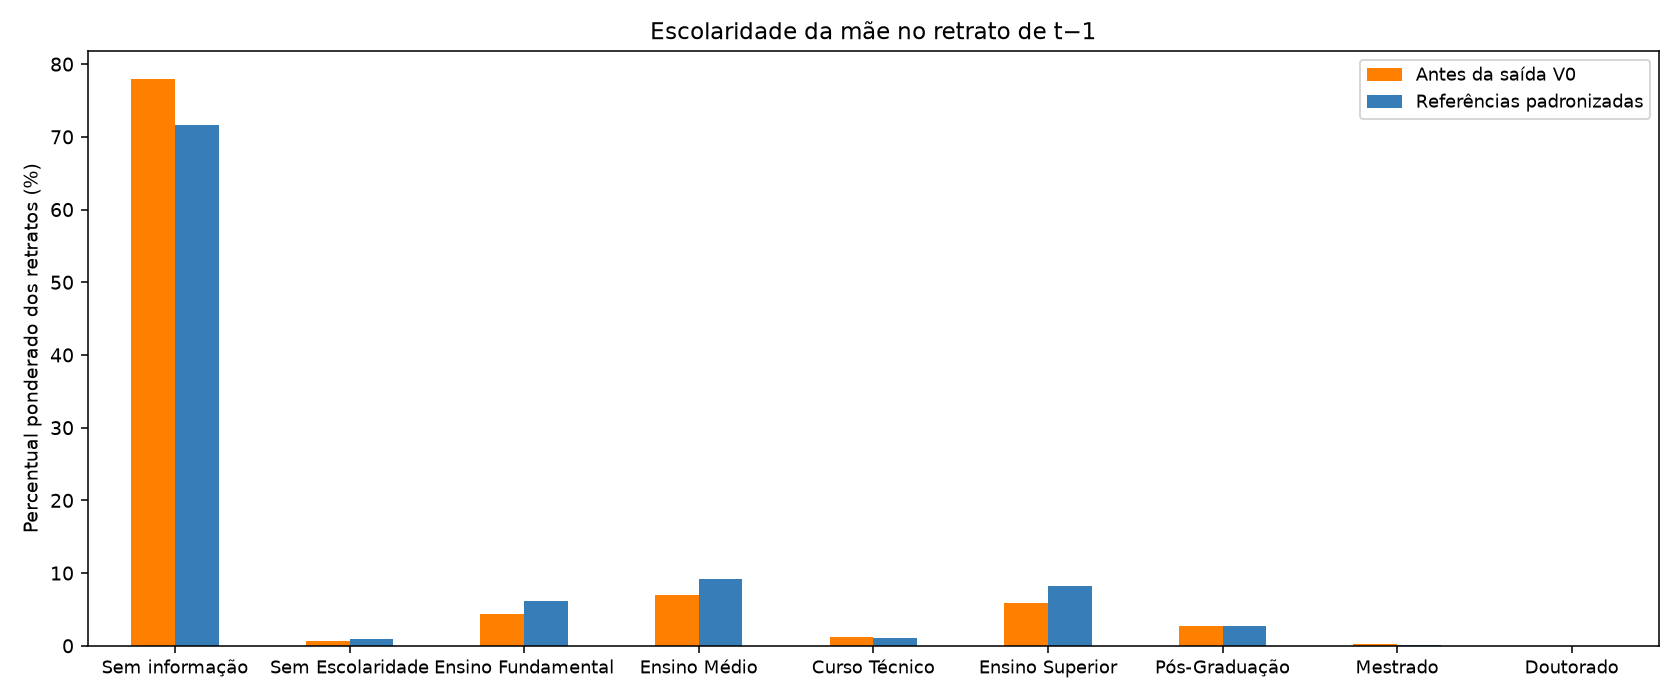

,casos_n,casos_%,referências_n,referências_%
categoria,,,,
Sem informação,1235,84.128,12788,78.292
Sem Escolaridade,12,0.817,154,0.878
Ensino Fundamental,57,3.883,1052,6.285
Ensino Médio,78,5.313,1402,7.642
Curso Técnico,24,1.635,251,1.356
Ensino Superior,49,3.338,808,4.243
Pós-Graduação,10,0.681,193,1.097
Mestrado,2,0.136,38,0.171
Doutorado,1,0.068,11,0.036


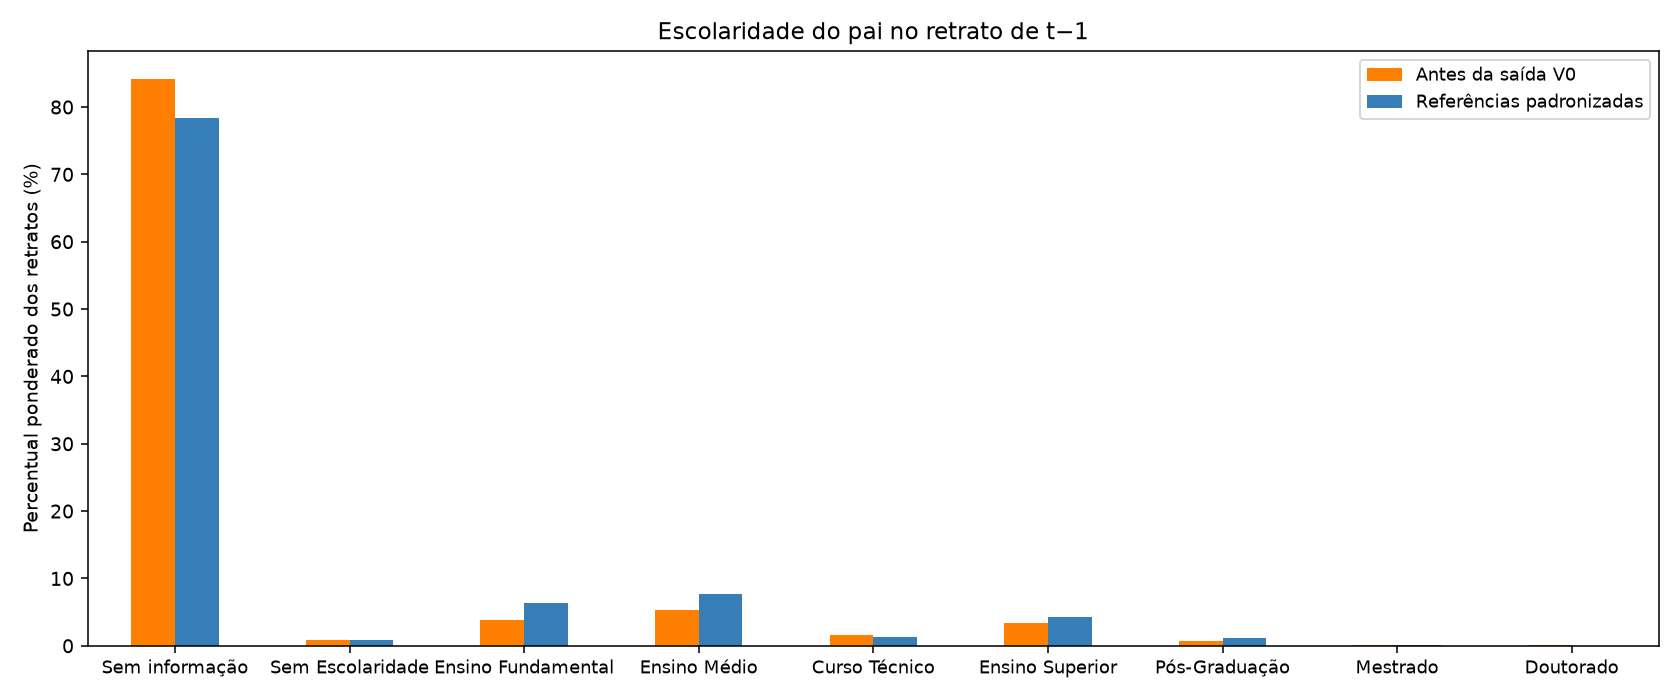

In [26]:
ordem_escolaridade = [
    "Sem informação", "Sem Escolaridade", "Ensino Fundamental", "Ensino Médio",
    "Curso Técnico", "Ensino Superior", "Pós-Graduação", "Mestrado", "Doutorado"
]
for coluna, pessoa, nome_figura in [
    ("IA70_02", "mãe", "16_escolaridade_mae"),
    ("IA70_06", "pai", "16_escolaridade_pai")
]:
    escolaridade = distribuicao_categorica(coluna, ordem_escolaridade)
    mostrar(f"Escolaridade da pessoa: {pessoa}", escolaridade)
    parentesco = "da mãe" if pessoa == "mãe" else "do pai"
    grafico_categorias(escolaridade, f"Escolaridade {parentesco} no retrato de t−1", nome_figura)


## 17. A saída acontece em diferentes momentos da trajetória?

Contamos semestres **distintos estritamente anteriores à primeira saída**, separando qualquer registro e registro acadêmico. Zero significa que não há semestre anterior observado na extração. Essa contagem não é tempo desde o ingresso nem uma estimativa de risco de saída.


,count,mean,std,min,25%,50%,75%,max
semestres_observados,3507.000,2.065,3.201,0.000,0.000,1.000,3.000,25.000
semestres_acadêmicos,3507.000,1.887,2.957,0.000,0.000,1.000,2.000,21.000


,sem_qualquer_semestre_anterior,sem_semestre_acadêmico_anterior
0,1613,1627


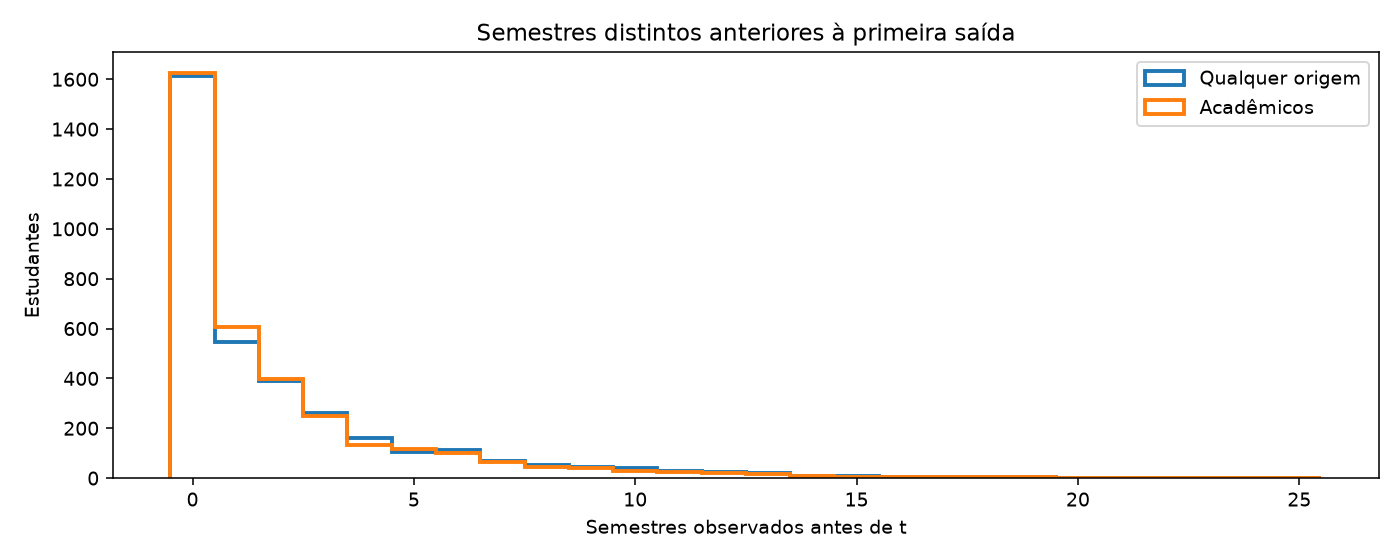

In [27]:
historico_anterior = df.loc[df.SEM.lt(df.PRIMEIRA_SAIDA)]
tempo_ate_saida = pd.DataFrame(index=alunos_saida)
tempo_ate_saida["semestres_observados"] = historico_anterior.groupby("HANDLEALUNO").SEM.nunique().reindex(alunos_saida, fill_value=0)
tempo_ate_saida["semestres_acadêmicos"] = historico_anterior.loc[
    historico_anterior.ORIGEMREGISTRO.eq("ACADEMICA")
].groupby("HANDLEALUNO").SEM.nunique().reindex(alunos_saida, fill_value=0)
mostrar("Semestres anteriores à primeira saída", tempo_ate_saida.describe().T)
mostrar("Sem histórico anterior", pd.DataFrame([{
    "sem_qualquer_semestre_anterior": int(tempo_ate_saida.semestres_observados.eq(0).sum()),
    "sem_semestre_acadêmico_anterior": int(tempo_ate_saida.semestres_acadêmicos.eq(0).sum())
}]))
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(-0.5, tempo_ate_saida.semestres_observados.max() + 1.5)
ax.hist(tempo_ate_saida.semestres_observados, bins=bins, histtype="step", linewidth=2, label="Qualquer origem")
ax.hist(tempo_ate_saida.semestres_acadêmicos, bins=bins, histtype="step", linewidth=2, label="Acadêmicos")
ax.set(title="Semestres distintos anteriores à primeira saída", xlabel="Semestres observados antes de t", ylabel="Estudantes")
ax.legend()
finalizar_figura(fig, "17_semestres_ate_saida")


## 18. Depois de uma saída, o estudante retorna?

Reingresso formal e matrícula acadêmica posterior são evidências diferentes. Contamos reingresso após a primeira e após a última saída, sempre em semestre estritamente posterior. Ausência de flag posterior não prova ausência de retorno; saídas e reingressos no mesmo semestre não têm ordem identificável.


,evidência,alunos
0,Reingresso após primeira saída,138
1,Reingresso após última saída,68
2,Matrícula acadêmica após primeira saída,398
3,Conclusão após primeira saída,142


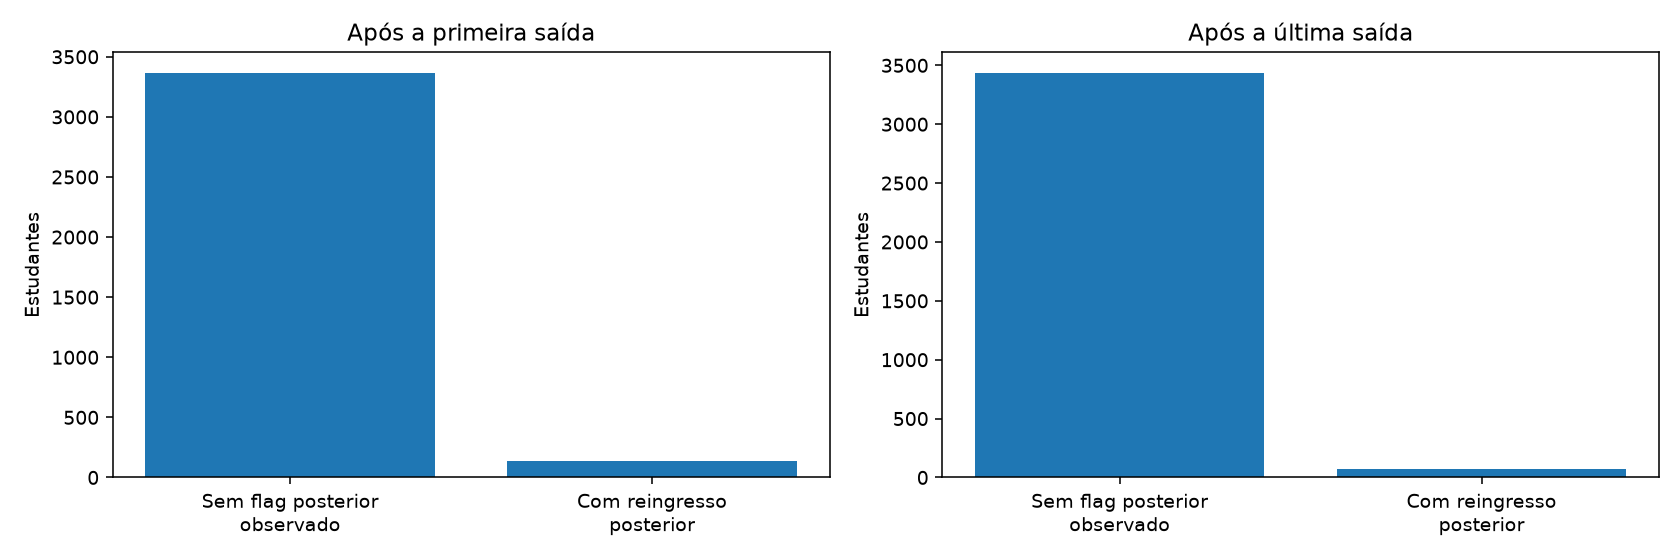

In [28]:
eventos_semestre["ULTIMA_SAIDA"] = eventos_semestre.HANDLEALUNO.map(ultima_saida)
reingresso_primeira = eventos_semestre.loc[
    eventos_semestre.SEM.gt(eventos_semestre.PRIMEIRA_SAIDA)
    & eventos_semestre.TEVEREINGRESSO.eq(1), "HANDLEALUNO"
].nunique()
reingresso_ultima = eventos_semestre.loc[
    eventos_semestre.SEM.gt(eventos_semestre.ULTIMA_SAIDA)
    & eventos_semestre.TEVEREINGRESSO.eq(1), "HANDLEALUNO"
].nunique()
matricula_posterior = academica.loc[
    academica.SEM.gt(academica.PRIMEIRA_SAIDA)
    & academica.MATRICULAEFETIVADA.eq("S"), "HANDLEALUNO"
].nunique()
retornos = pd.DataFrame([
    {"evidência": "Reingresso após primeira saída", "alunos": reingresso_primeira},
    {"evidência": "Reingresso após última saída", "alunos": reingresso_ultima},
    {"evidência": "Matrícula acadêmica após primeira saída", "alunos": matricula_posterior},
    {"evidência": "Conclusão após primeira saída", "alunos": int(primeira_conclusao.gt(primeira_saida).sum())}
])
mostrar("Evidências posteriores — grupos sobrepostos", retornos)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, positivos, titulo in zip(
    axes, [reingresso_primeira, reingresso_ultima],
    ["Após a primeira saída", "Após a última saída"]
):
    ax.bar(["Sem flag posterior\nobservado", "Com reingresso\nposterior"], [len(alunos_saida) - positivos, positivos])
    ax.set(title=titulo, ylabel="Estudantes")
finalizar_figura(fig, "18_reingresso_posterior")


In [29]:
NOVAS_FLAGS = {
    "TEVEREMATRICULA": "Rematrícula",
    "TEVEFALECIMENTO": "Falecimento",
    "TEVEPRAZOESGOTADO": "Prazo de integralização esgotado",
    "TEVEAFASTAMENTOSEMOCORRENCIA": "Afastamento sem ocorrência",
}
ORDEM_MOMENTO = ["sem saída", "antes da 1ª saída", "mesmo semestre", "depois da 1ª saída"]
linhas = []
for coluna, nome in NOVAS_FLAGS.items():
    positivos = df.loc[df[coluna].eq(1), ["HANDLEALUNO", "SEM", "PRIMEIRA_SAIDA"]].drop_duplicates(["HANDLEALUNO", "SEM"])
    momento = pd.Series(np.select(
        [positivos.PRIMEIRA_SAIDA.isna(),
         positivos.SEM.lt(positivos.PRIMEIRA_SAIDA),
         positivos.SEM.eq(positivos.PRIMEIRA_SAIDA)],
        ORDEM_MOMENTO[:3], default=ORDEM_MOMENTO[3]
    ), index=positivos.index)
    for rotulo in ORDEM_MOMENTO:
        grupo = positivos.loc[momento.eq(rotulo)]
        linhas.append({
            "ocorrência": nome, "momento": rotulo,
            "alunos_semestre": len(grupo), "alunos": grupo.HANDLEALUNO.nunique()
        })
mostrar("Novas ocorrências em relação à primeira saída", pd.DataFrame(linhas))

,ocorrência,momento,alunos_semestre,alunos
0,Rematrícula,sem saída,227,214
1,Rematrícula,antes da 1ª saída,105,94
2,Rematrícula,mesmo semestre,21,21
3,Rematrícula,depois da 1ª saída,25,23
4,Falecimento,sem saída,13,13
5,Falecimento,antes da 1ª saída,0,0
6,Falecimento,mesmo semestre,0,0
7,Falecimento,depois da 1ª saída,1,1
8,Prazo de integralização esgotado,sem saída,17,17
9,Prazo de integralização esgotado,antes da 1ª saída,8,8


In [30]:
# ---- Afastamento sem ocorrência depois da 1ª saída: o que vem depois? ----
afast = df.loc[
    df.TEVEAFASTAMENTOSEMOCORRENCIA.eq(1) & df.SEM.gt(df.PRIMEIRA_SAIDA),
    ["HANDLEALUNO", "SEM"]
].drop_duplicates()
inicio_afast = afast.groupby("HANDLEALUNO").SEM.min()
fim_afast = afast.groupby("HANDLEALUNO").SEM.max()
hist_afast = df.loc[df.HANDLEALUNO.isin(inicio_afast.index)].copy()
hist_afast["INICIO_AFAST"] = hist_afast.HANDLEALUNO.map(inicio_afast)
hist_afast["FIM_AFAST"] = hist_afast.HANDLEALUNO.map(fim_afast)


def alunos_onde(condicao):
    return hist_afast.loc[condicao.fillna(False).astype(bool), "HANDLEALUNO"].nunique()


mostrar("Afastamento sem ocorrência após a 1ª saída — evidências posteriores", pd.DataFrame([
    {"situação": "Alunos com afastamento após a 1ª saída", "alunos": len(inicio_afast)},
    {"situação": "Reingresso formal depois do 1º afastamento",
     "alunos": alunos_onde(hist_afast.SEM.gt(hist_afast.INICIO_AFAST) & hist_afast.TEVEREINGRESSO.eq(1))},
    {"situação": "Matrícula efetivada depois do último afastamento",
     "alunos": alunos_onde(hist_afast.SEM.gt(hist_afast.FIM_AFAST)
                           & hist_afast.ORIGEMREGISTRO.eq("ACADEMICA")
                           & hist_afast.MATRICULAEFETIVADA.eq("S"))},
    {"situação": "Conclusão depois do 1º afastamento",
     "alunos": alunos_onde(hist_afast.SEM.gt(hist_afast.INICIO_AFAST) & hist_afast.CONCLUSAO.eq(1))},
    {"situação": "Último afastamento no último semestre da base",
     "alunos": int(fim_afast.eq(df.SEM.max()).sum())},
]))
mostrar("Afastamento — semestres entre a 1ª saída e o 1º afastamento",
        (inicio_afast - primeira_saida.reindex(inicio_afast.index)).astype(int)
        .value_counts().sort_index().rename_axis("semestres").reset_index(name="alunos"))
mostrar("Afastamento — semestres afastados por aluno",
        afast.groupby("HANDLEALUNO").size().value_counts().sort_index()
        .rename_axis("semestres").reset_index(name="alunos"))

# ---- Prazo esgotado antes da 1ª saída: que saída vem depois? ----
prazo_antes = (
    df.loc[df.TEVEPRAZOESGOTADO.eq(1) & df.SEM.lt(df.PRIMEIRA_SAIDA),
           ["HANDLEALUNO", "SEM", "PRIMEIRA_SAIDA"]]
    .sort_values("SEM").drop_duplicates("HANDLEALUNO")
    .rename(columns={"SEM": "SEM_PRAZO"})
)
flags_primeira_saida = (
    eventos_semestre.loc[eventos_semestre.SEM.eq(eventos_semestre.PRIMEIRA_SAIDA),
                         ["HANDLEALUNO"] + EVENTOS_SAIDA_PRINCIPAIS]
    .set_index("HANDLEALUNO")
)
positivos_saida = flags_primeira_saida.loc[prazo_antes.HANDLEALUNO].eq(1).fillna(False).astype(bool)
prazo_antes["TIPO_PRIMEIRA_SAIDA"] = positivos_saida.apply(
    lambda linha: " + ".join(coluna.replace("TEVE", "") for coluna in linha.index[linha]), axis=1
).values
prazo_antes["SEMESTRES_ATE_SAIDA"] = (prazo_antes.PRIMEIRA_SAIDA - prazo_antes.SEM_PRAZO).astype(int).values
entre = academica.merge(prazo_antes[["HANDLEALUNO", "SEM_PRAZO"]], on="HANDLEALUNO")
entre = entre.loc[entre.SEM.gt(entre.SEM_PRAZO) & entre.SEM.lt(entre.PRIMEIRA_SAIDA)]
prazo_antes["MATRICULA_ENTRE_PRAZO_E_SAIDA"] = prazo_antes.HANDLEALUNO.isin(entre.HANDLEALUNO).values
mostrar("Prazo esgotado antes da 1ª saída", (
    prazo_antes.groupby(["TIPO_PRIMEIRA_SAIDA", "SEMESTRES_ATE_SAIDA", "MATRICULA_ENTRE_PRAZO_E_SAIDA"])
    .size().reset_index(name="alunos")
))

,situação,alunos
0,Alunos com afastamento após a 1ª saída,73
1,Reingresso formal depois do 1º afastamento,71
2,Matrícula efetivada depois do último afastamento,68
3,Conclusão depois do 1º afastamento,15
4,Último afastamento no último semestre da base,3


,semestres,alunos
0,1,62
1,2,1
2,3,1
3,4,2
4,5,1
5,6,1
6,10,2
7,11,2
8,13,1


,semestres,alunos
0,1,36
1,2,15
2,3,8
3,4,3
4,5,2
5,6,5
6,8,1
7,9,1
8,11,1
9,13,1


,TIPO_PRIMEIRA_SAIDA,SEMESTRES_ATE_SAIDA,MATRICULA_ENTRE_PRAZO_E_SAIDA,alunos
0,ABANDONO,2,True,1
1,ABANDONO,3,True,1
2,ABANDONO,5,True,2
3,DESISTENCIA,1,False,1
4,DESISTENCIA,2,True,1
5,DESISTENCIA,3,True,1
6,DESISTENCIA,4,True,1


In [31]:
# ---- Prazo esgotado sem nenhuma saída: o vínculo terminou? ----
prazo_sem_saida = (
    df.loc[df.TEVEPRAZOESGOTADO.eq(1) & df.PRIMEIRA_SAIDA.isna(), ["HANDLEALUNO", "SEM"]]
    .sort_values("SEM").drop_duplicates("HANDLEALUNO")
    .rename(columns={"SEM": "SEM_PRAZO"})
)
hist_prazo = df.merge(prazo_sem_saida, on="HANDLEALUNO")
ultimo_semestre_aluno = hist_prazo.groupby("HANDLEALUNO").SEM.max()
mostrar("Prazo esgotado sem saída — evidências posteriores", pd.DataFrame([
    {"situação": "Alunos com prazo esgotado e sem saída", "alunos": len(prazo_sem_saida)},
    {"situação": "Matrícula efetivada depois do prazo",
     "alunos": hist_prazo.loc[hist_prazo.SEM.gt(hist_prazo.SEM_PRAZO)
                              & hist_prazo.ORIGEMREGISTRO.eq("ACADEMICA")
                              & hist_prazo.MATRICULAEFETIVADA.eq("S"), "HANDLEALUNO"].nunique()},
    {"situação": "Conclusão no semestre do prazo ou depois",
     "alunos": hist_prazo.loc[hist_prazo.SEM.ge(hist_prazo.SEM_PRAZO)
                              & hist_prazo.CONCLUSAO.eq(1).fillna(False), "HANDLEALUNO"].nunique()},
    {"situação": "Nenhum registro depois do prazo",
     "alunos": int(ultimo_semestre_aluno.eq(prazo_sem_saida.set_index("HANDLEALUNO").SEM_PRAZO
                                            .reindex(ultimo_semestre_aluno.index)).sum())},
    {"situação": "Prazo no último semestre da base",
     "alunos": int(prazo_sem_saida.SEM_PRAZO.eq(df.SEM.max()).sum())},
]))

,situação,alunos
0,Alunos com prazo esgotado e sem saída,17
1,Matrícula efetivada depois do prazo,15
2,Conclusão no semestre do prazo ou depois,13
3,Nenhum registro depois do prazo,1
4,Prazo no último semestre da base,0


## 19. Alguns estudantes apresentam mais de um evento de saída?

Contamos quantos **semestres distintos** têm flag de saída para cada estudante. Vários semestres positivos não identificam, sozinhos, episódios independentes: um evento pode ser reiterado, e um retorno pode anteceder outra saída.


,semestres_positivos
count,3507.000
mean,1.063
std,0.265
min,1.000
25%,1.000
50%,1.000
75%,1.000
max,4.000


Estudantes com mais de um semestre positivo: 202


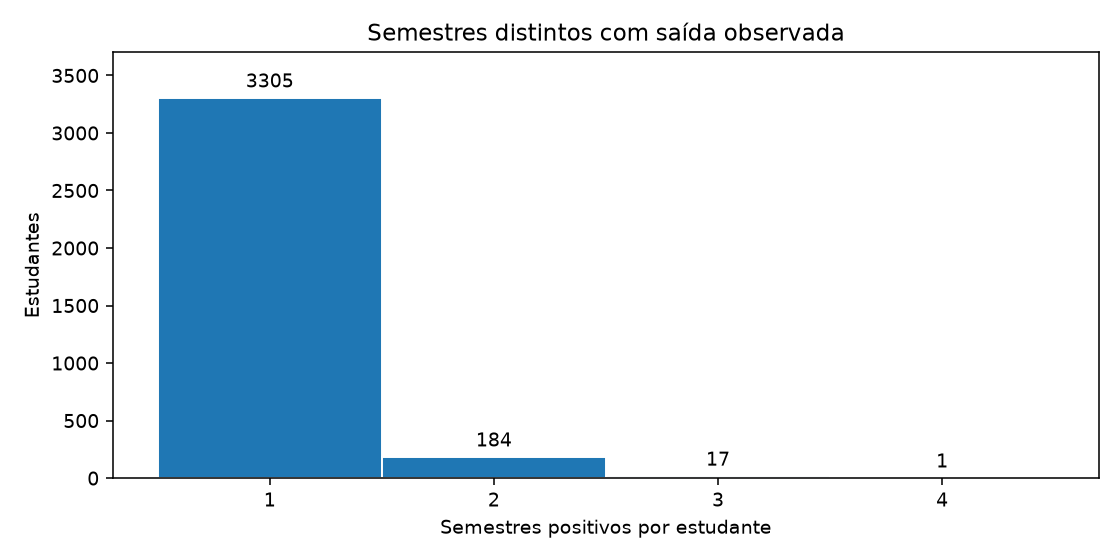

In [32]:
quantidade_saidas = eventos_semestre.groupby("HANDLEALUNO").EVENTO_SAIDA.apply(lambda serie: serie.eq(1).sum())
quantidade_saidas = quantidade_saidas.loc[quantidade_saidas.gt(0)]
mostrar("Semestres com saída por aluno", quantidade_saidas.describe().to_frame("semestres_positivos"))
print(f"Estudantes com mais de um semestre positivo: {int(quantidade_saidas.gt(1).sum())}")
fig, ax = plt.subplots(figsize=(8, 4))
contagens, limites, barras = ax.hist(
    quantidade_saidas,
    bins=np.arange(0.5, quantidade_saidas.max() + 1.5),
    edgecolor="white"
)
ax.bar_label(barras, labels=[str(int(valor)) for valor in contagens], padding=3)
ax.set_xticks(np.arange(1, quantidade_saidas.max() + 1))
ax.margins(y=0.12)
ax.set(title="Semestres distintos com saída observada", xlabel="Semestres positivos por estudante", ylabel="Estudantes")
finalizar_figura(fig, "19_multiplos_semestres_saida")


## 20. A queda no CRE começa antes do semestre da saída?

Alinhamos os três semestres calendário `t−3`, `t−2` e `t−1`, com registro acadêmico único e sem conclusão até `t`. Mostramos a cobertura disponível, mas a trajetória principal usa **os mesmos alunos com CRE informado nos três semestres**.

As sensibilidades de estabilidade são separadas da elegibilidade V1/V2. Curso estável exige a mesma `SIGLACURSO` nos três registros; vínculo curricular estável exige o mesmo `HANDLEALUNOCURRICULO`, com informação completa. Essas condições se referem à janela anterior e não ao semestre da saída ou a toda a carreira.


,n,média,mediana
DISTANCIA,,,
-3.000,872,35.174,34.785
-2.000,1184,31.553,29.560
-1.000,1282,23.709,19.860


,painel,distância,n_alunos,média_CRE,mediana_CRE,excluídos_vs_T0
0,T0 painel completo,-3,466,33.303,32.195,0
1,T0 painel completo,-2,466,29.350,28.010,0
2,T0 painel completo,-1,466,21.777,17.485,0
3,T1 curso estável,-3,433,32.959,31.440,33
4,T1 curso estável,-2,433,29.123,27.500,33
5,T1 curso estável,-1,433,22.004,17.640,33
6,T2 vínculo curricular estável,-3,342,33.570,32.465,124
7,T2 vínculo curricular estável,-2,342,29.719,28.345,124
8,T2 vínculo curricular estável,-1,342,22.522,18.810,124


,painel,alunos,variação_média_t_menos_3_a_1,percentual_com_queda
0,T0 painel completo,466,-11.526,62.876
1,T1 curso estável,433,-10.955,61.894
2,T2 vínculo curricular estável,342,-11.047,61.696


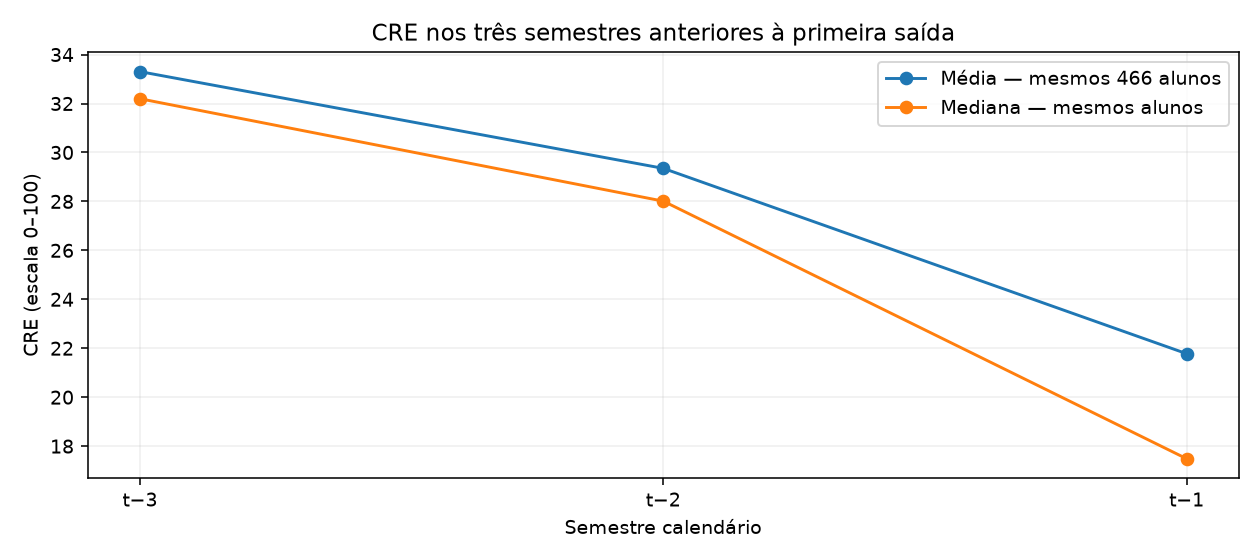

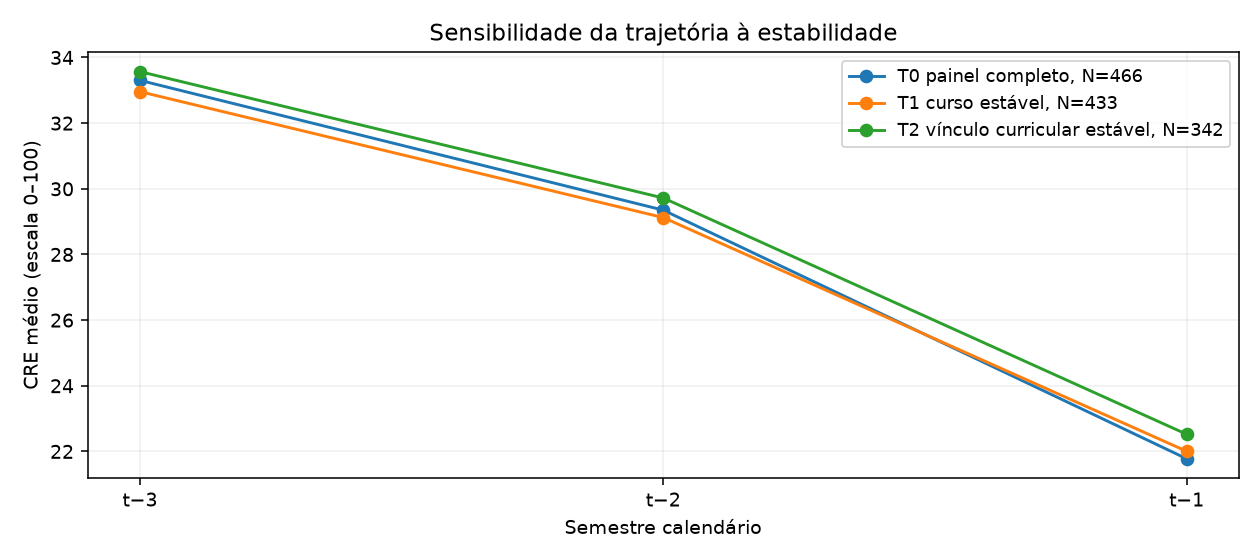

In [33]:
trajetorias = academica_unica.copy()
trajetorias["CONCLUSAO_INICIAL"] = trajetorias.HANDLEALUNO.map(primeira_conclusao)
trajetorias["DISTANCIA"] = trajetorias.SEM - trajetorias.PRIMEIRA_SAIDA
trajetorias = trajetorias.loc[
    trajetorias.DISTANCIA.isin([-3, -2, -1])
    & (trajetorias.CONCLUSAO_INICIAL.isna()
       | trajetorias.CONCLUSAO_INICIAL.gt(trajetorias.PRIMEIRA_SAIDA))
].copy()
disponivel = trajetorias.groupby("DISTANCIA").CRENOSEMESTRE_NUM.agg(n="count", média="mean", mediana="median")
mostrar("CRE disponível em cada distância — N variável", disponivel)
painel = trajetorias.pivot(index="HANDLEALUNO", columns="DISTANCIA", values="CRENOSEMESTRE_NUM")
painel = painel.reindex(columns=[-3, -2, -1]).dropna()
trio = trajetorias.loc[trajetorias.HANDLEALUNO.isin(painel.index)]


def alunos_estaveis(coluna):
    grupos = trio.groupby("HANDLEALUNO")[coluna]
    estavel = grupos.count().eq(3) & grupos.nunique().eq(1)
    return estavel.index[estavel]


paineis = {
    "T0 painel completo": painel,
    "T1 curso estável": painel.loc[painel.index.isin(alunos_estaveis("SIGLACURSO"))],
    "T2 vínculo curricular estável": painel.loc[painel.index.isin(alunos_estaveis("HANDLEALUNOCURRICULO"))]
}
resumo_trajetorias = pd.DataFrame([
    {
        "painel": nome, "distância": distancia, "n_alunos": len(amostra),
        "média_CRE": amostra[distancia].mean(),
        "mediana_CRE": amostra[distancia].median(),
        "excluídos_vs_T0": len(painel) - len(amostra)
    }
    for nome, amostra in paineis.items()
    for distancia in [-3, -2, -1]
])
mostrar("Trajetórias com os mesmos alunos em cada painel", resumo_trajetorias)
variacao_trajetorias = pd.DataFrame([
    {
        "painel": nome, "alunos": len(amostra),
        "variação_média_t_menos_3_a_1": (amostra[-1] - amostra[-3]).mean(),
        "percentual_com_queda": (amostra[-1] < amostra[-3]).mean() * 100
    }
    for nome, amostra in paineis.items()
])
mostrar("Variação individual por painel", variacao_trajetorias)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot([-3, -2, -1], painel.mean(), marker="o", label=f"Média — mesmos {len(painel)} alunos")
ax.plot([-3, -2, -1], painel.median(), marker="o", label="Mediana — mesmos alunos")
ax.set_xticks([-3, -2, -1], ["t−3", "t−2", "t−1"])
ax.set(title="CRE nos três semestres anteriores à primeira saída", xlabel="Semestre calendário", ylabel="CRE (escala 0–100)")
ax.legend()
ax.grid(alpha=0.2)
finalizar_figura(fig, "20_trajetoria_mesmos_alunos")
fig, ax = plt.subplots(figsize=(9, 4))
for nome, amostra in paineis.items():
    ax.plot([-3, -2, -1], amostra.mean(), marker="o", label=f"{nome}, N={len(amostra)}")
ax.set_xticks([-3, -2, -1], ["t−3", "t−2", "t−1"])
ax.set(title="Sensibilidade da trajetória à estabilidade", xlabel="Semestre calendário", ylabel="CRE médio (escala 0–100)")
ax.legend(fontsize=9)
ax.grid(alpha=0.2)
finalizar_figura(fig, "20_sensibilidades_estabilidade")


## 21. Antes de modelar, o que ainda precisamos saber sobre a qualidade dos dados?

A ausência é medida nas colunas originais, sem repetir as derivadas numéricas. Além de nulos, reconhecemos categorias sem informação. Os dois tipos são apresentados separadamente. Ainda precisamos confirmar a temporalidade dos indicadores, a unidade das ocorrências e as janelas das contagens acadêmicas.


,nulos_%,sem_informação_não_nulo_%,ausência_total_%
variável,,,
IA12_01,95.936,0.000,95.936
IA09_02,94.502,0.000,94.502
APROVEIT,85.147,0.000,85.147
IA70_06,74.280,8.473,82.753
IA70_02,74.280,3.036,77.316
IA70_04,74.280,2.443,76.723
IA70_03,74.280,0.000,74.280
IA70_05,74.280,0.000,74.280
IA70_01,74.280,0.000,74.280


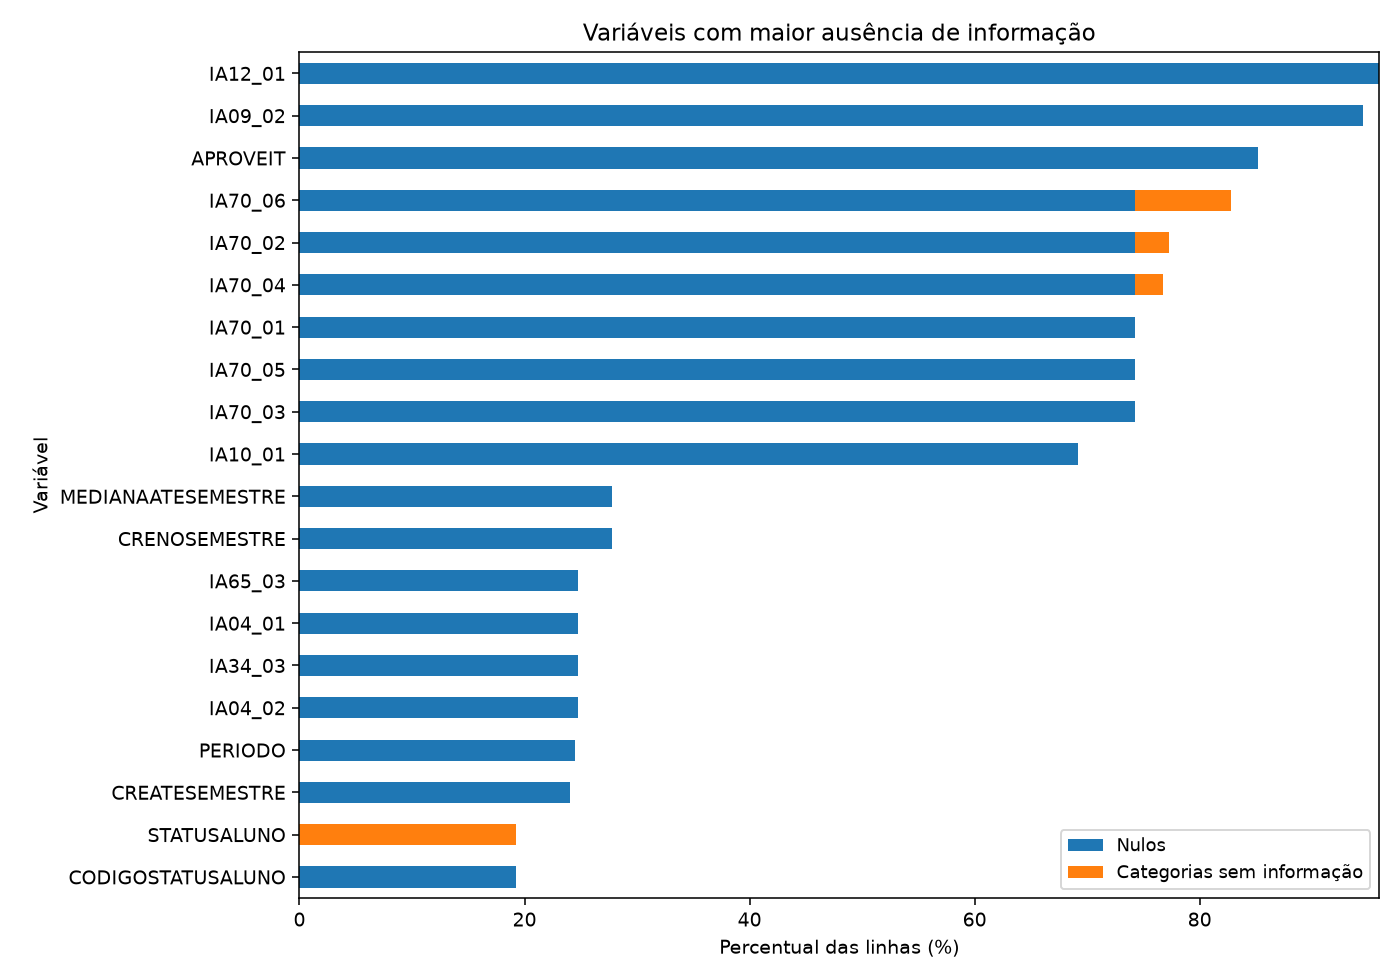

,item,pendência
0,Transferência/afastamento,Legenda: TEVETRASAFASTAMENTO; CSV: TEVETRANSAFASTAMENTO
1,ORIGEMREGISTRO / QUANTIDADEOCORRENCIAS,Definições e unidade não documentadas na legenda
2,Curso GAE,Sigla não documentada na legenda
3,Contagens de disciplinas,"Confirmar janelas, aproveitamentos e mudanças de vínculo"
4,"Rendas, finanças e status",Confirmar data de coleta e atualização retrospectiva


In [34]:
qualidade_ausencias = pd.DataFrame([
    {
        "variável": coluna,
        "nulos_%": raw[coluna].isna().mean() * 100,
        "sem_informação_não_nulo_%": (
            raw[coluna].notna() & raw[coluna].str.strip().str.lower().isin(TOKENS_AUSENTES)
        ).mean() * 100
    }
    for coluna in raw if not coluna.startswith("DATA")
]).set_index("variável")
qualidade_ausencias["ausência_total_%"] = qualidade_ausencias["nulos_%"] + qualidade_ausencias["sem_informação_não_nulo_%"]
top_ausencias = qualidade_ausencias.sort_values("ausência_total_%", ascending=False).head(20)
mostrar("Ausência de informação — colunas originais", top_ausencias)
fig, ax = plt.subplots(figsize=(10, 7))
top_ausencias.sort_values("ausência_total_%")[["nulos_%", "sem_informação_não_nulo_%"]].rename(columns={
    "nulos_%": "Nulos", "sem_informação_não_nulo_%": "Categorias sem informação"
}).plot.barh(stacked=True, ax=ax)
ax.set(title="Variáveis com maior ausência de informação", xlabel="Percentual das linhas (%)", ylabel="Variável")
ax.legend(fontsize=9)
finalizar_figura(fig, "21_ausencias")
mostrar("Pendências de documentação", pd.DataFrame([
    {"item": "Transferência/afastamento", "pendência": "Legenda: TEVETRASAFASTAMENTO; CSV: TEVETRANSAFASTAMENTO"},
    {"item": "ORIGEMREGISTRO / QUANTIDADEOCORRENCIAS", "pendência": "Definições e unidade não documentadas na legenda"},
    {"item": "Curso GAE", "pendência": "Sigla não documentada na legenda"},
    {"item": "Contagens de disciplinas", "pendência": "Confirmar janelas, aproveitamentos e mudanças de vínculo"},
    {"item": "Rendas, finanças e status", "pendência": "Confirmar data de coleta e atualização retrospectiva"}
]))


## 22. O que a análise exploratória nos mostrou até aqui?

A base permite acompanhar trajetórias, mas um evento de saída pode coexistir com retorno ou conclusão. O CRE e a frequência diferem entre grupos no retrato anterior, e a magnitude da diferença de frequência depende bastante da elegibilidade. A queda média de CRE também aparece nos painéis com curso e vínculo estáveis.

As análises financeiras e familiares têm cobertura limitada. As contagens de aprovação/reprovação precisam de validação antes de serem tratadas como indicadores do semestre. Permanecem pendentes a definição institucional de evasão, o tratamento dos retornos e transferências e o intervalo sem retorno.

Os resultados descrevem os recortes observados. Seguimento incompleto, seleção de alunos com histórico disponível, referências repetidas e possíveis atualizações retrospectivas limitam a interpretação.


In [35]:
cre_v1 = sensibilidades.loc[
    sensibilidades["versão"].eq("V1")
    & sensibilidades.indicador.eq("CRENOSEMESTRE_NUM")
].iloc[0]
freq_v1 = sensibilidades.loc[
    sensibilidades["versão"].eq("V1")
    & sensibilidades.indicador.eq("IA04_01_NUM")
].iloc[0]
display(Markdown(
    f"Com status Ativo e matrícula efetivada em t−1 (V1), o CRE médio é "
    f"{cre_v1['média_casos']:.2f} nos casos e {cre_v1['média_refs_padronizada']:.2f} "
    f"nas referências padronizadas. A frequência é {freq_v1['média_casos']:.2f}% "
    f"e {freq_v1['média_refs_padronizada']:.2f}%, respectivamente. "
    f"No painel completo de {len(painel)} alunos, o CRE médio passa de "
    f"{painel[-3].mean():.2f} em t−3 para {painel[-1].mean():.2f} em t−1."
))

# Asserções de consistência sem exibir linhas individuais.
assert len(casos_v1) <= len(casos_v0)
assert len(refs_v2) <= len(refs_v1)
assert all(amostra.notna().all().all() for amostra in paineis.values())
assert len(FIGURAS) == len(set(FIGURAS))
for nome, path in FONTES.items():
    assert hashlib.sha256(path.read_bytes()).hexdigest() == hashes_antes[nome]


Com status Ativo e matrícula efetivada em t−1 (V1), o CRE médio é 23.82 nos casos e 51.74 nas referências padronizadas. A frequência é 78.92% e 90.57%, respectivamente. No painel completo de 466 alunos, o CRE médio passa de 33.30 em t−3 para 21.78 em t−1.

### Pontos para discussão da pesquisa

Confirmar com a instituição a unidade dos eventos, a ordenação dos registros acadêmicos, a temporalidade dos status e as janelas dos indicadores. Com o orientador, discutir as alternativas de elegibilidade, estabilidade e desfecho. A escolha de uma definição definitiva e a etapa de modelagem permanecem fora desta análise.


## Referências utilizadas como apoio

As referências abaixo foram utilizadas para orientar as perguntas da análise e a interpretação dos resultados, e não para impor à base do Inatel um comportamento que veio de outra instituição.

- **TINTO, Vincent.** *Leaving College: Rethinking the Causes and Cures of Student Attrition*. University of Chicago Press, 1994. Utilizamos principalmente a perspectiva de permanência e saída como processos relacionados à trajetória do estudante.
- **TINTO, Vincent.** *Completing College: Rethinking Institutional Action*. University of Chicago Press, 2012. Utilizamos como complemento para discutir experiência acadêmica, envolvimento e condições relacionadas à permanência.
- **OLIVEIRA, R. S.; MEDEIROS, F. P. A.** Trabalho sobre predição de evasão com mineração de dados educacionais e autoavaliação institucional. Foi utilizado como referência metodológica complementar para a utilização de dados acadêmicos e técnicas de aprendizado de máquina.
- **BARBOSA et al.** *Previsão da Evasão Escolar através da Análise de Dados e Aprendizagem de Máquina: um estudo de caso*. Utilizado como referência de outro estudo de caso que trabalha com dados educacionais e aprendizado de máquina.
- **IBM — CRISP-DM.** Utilizada como referência para a organização das etapas de entendimento e preparação dos dados antes da modelagem.

A ideia central que orientou esta etapa foi simples: primeiro entender os dados e o fenômeno que estamos estudando; depois definir com cuidado o desfecho; e só então partir para a modelagem.
